# 05 · Modelling Optimization
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

| # | Notebook | Isi |
|---|---|---|
| 04 | Modelling | baseline M0–M4, OOF, gerbang v0, anomali, skor v0 |
| **05** | **Modelling Optimization** | **notebook ini — perbaikan LR, HPO, ensemble, imbalance, kalibrasi, conformal, prospect, gerbang, penjelasan, skor v1** |
| 06 | Model Evaluation | evaluasi **sekali** di test & ground truth |
| 07 | Post-evaluation & Remodelling | analisis kesalahan |
| 08 | Segmentasi & Opportunity Score | K-means 3 segmen, skor per segmen |

## Pertanyaan yang dijawab
1. **Bisakah champion LR dibuat patuh logika bisnis** tanpa kehilangan kinerja? NB04: LR gagal uji arah di 8 dari 23 fitur karena fitur yang saling berkorelasi.
2. **Seberapa banyak HPO menolong** RF / XGBoost / LightGBM?
3. **Bobot kelas vs SMOTE** — mana yang lebih baik untuk recall High dan kalibrasi?
4. **Apakah ensemble** mengalahkan model tunggal secara bermakna?
5. **Kalibrasi + conformal**: berapa % kasus bisa diputuskan otomatis, dan apakah jaminan cakupan 90% berlaku per segmen?
6. **Prospect**: apakah *importance weighting* mengoreksi 60% prospect yang di-flag High di skor v0?

## Keputusan metode (hasil diskusi 11 Okt)
- **Tanpa feature selection umum (RFE).** Set fitur sudah diuji di NB03 (ablation & leave-one-group-out). Dengan 800 baris dan ±110 kasus High, RFE tidak stabil dan butuh *nested* CV. Yang dikerjakan: **pemangkasan fitur kolinear yang beralasan bisnis** untuk memperbaiki arah koefisien LR. RFECV hanya lampiran pembanding (bagian Q, mati secara default).
- **Feature importance untuk penjelasan, bukan seleksi**: permutation importance per kelompok fitur + SHAP.
- **HPO dengan Optuna (TPE + median pruner)**, objektif **log-loss berbobot seimbang** di 5-fold `cv_fold`. Macro-F1 terlalu berisik untuk memilih hiperparameter (valid hanya 27 kasus High). Keputusan kelas diatur terpisah di lapis 3 (ambang recall High).
- **Dua skema fold**: `cv_fold` untuk **memilih** (HPO, grid LR); fold baru (StratifiedGroupKFold, seed lain, per grup usaha) untuk **menilai** dan gerbang promosi. Ini mengurangi bias seleksi (Varma & Simon, 2006; Cawley & Talbot, 2010) tanpa biaya penuh nested CV.

## Aturan yang dijaga (checklist §11)
- Label test dikunci; test tidak dipakai untuk apa pun di NB05.
- PeerZScaler, SMOTE, bobot, kalibrasi, conformal, dan ambang di-fit di data latih/OOF train+valid.
- `gt_*` dan `eval_targets/` tidak dibaca di NB05.

## Input & output (relatif ke akar proyek)
| | Path | Asal / pemakai |
|---|---|---|
| **input** | `data/processed/features_risk.csv.gz`, `feature_sets.json` | NB03 (+ `set_noncredit`, `set_prospect` dari NB04) |
| **input** | `data/raw/companies.csv` | kolom `business_group` untuk fold penilaian per grup usaha (opsional) |
| **input** | `models/04_modelling/manifest.json`, `M1__set_core.joblib` | champion & `C` LR dari NB04 |
| **input** | `outputs/04_modelling/oof_results.csv`, `predictions/` | hasil OOF NB04 (pembanding) |
| **input** | `outputs/scores/risk_scores.csv` (v0) | skor NB04, diarsipkan ke `risk_scores_v0_nb04.csv` sebelum ditimpa |
| **input** | `src/features.py`, `src/modelling.py`, `src/modelling_nb05.py` | PeerZScaler, OrdinalMonotone, RiskModel / kalibrator / conformal |
| **output** | `outputs/05_optimization/*.csv`, `hpo_best_params.json`, `SUMMARY.md`, `figures/*.png` | grid LR, HPO, imbalance, ensemble, kalibrasi, gerbang, registri |
| **output** | `outputs/scores/risk_scores.csv` (v1), `shadow_log.csv` | skor dashboard v1; arsip v0: `risk_scores_v0_nb04.csv`, `shadow_log_v0_nb04.csv` |
| **output** | `models/05_optimization/` | `champion__<set>.joblib` (terkalibrasi), `domain_model.joblib`, `manifest.json` |

Jalankan NB03 → NB04 dulu. Waktu jalan ±5–10 menit (terbanyak di HPO; kecilkan `N_TRIALS` untuk uji cepat).

**Daftar isi:** A. Setup · B. Data, fold, hasil NB04 · C. Mesin evaluasi · D. Baseline di fold penilaian · E. Perbaikan LR · F. HPO pohon (Optuna) · G. Penilaian ulang · H. Bobot kelas vs SMOTE · I. Ensemble · J. Kalibrasi · K. Lapis 2–3 · L. Gerbang promosi · M. Non-kredit & prospect · N. Penjelasan · O. Model final & skor v1 · P. Ringkasan & checklist · Q. Lampiran RFECV · Daftar pustaka

## A. Setup
Pustaka tambahan (optuna, shap, imbalanced-learn) sudah ada di `pyproject.toml` → `uv sync`. Bila tidak terpasang:
- Optuna → random search (`numpy`) dengan ruang pencarian yang sama;
- SHAP → kontribusi linear eksak untuk LR (Linear SHAP) atau atribusi oklusi;
- imbalanced-learn → SMOTE sederhana bawaan `src/modelling_nb05.py`.

**Konfigurasi** ada di sel berikut: jumlah percobaan HPO, grid LR, target recall, α conformal.

In [1]:
import json, shutil, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import joblib
import sklearn
from scipy import stats
from scipy.optimize import minimize
from threadpoolctl import threadpool_limits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, adjusted_rand_score, log_loss
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import xgboost as xgb; HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    import lightgbm as lgb; HAS_LGB = True
except ImportError:
    HAS_LGB = False
try:
    import optuna; HAS_OPTUNA = True
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:
    HAS_OPTUNA = False
try:
    import shap; HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)
threadpool_limits(1)

SEED = 2026
T0 = time.time()

# ---- konfigurasi ----
N_TRIALS = {'M2': 12, 'M3': 30, 'M4': 30}          # percobaan HPO per model pohon (Random Forest lebih lambat → lebih sedikit)
LR_GRID = {'C': [0.03, 0.1, 0.3, 1.0], 'l1_ratio': [0.0, 0.3, 0.7]}   # l1_ratio 0 = L2 biasa; > 0 = elastic net
TARGET_RECALL = 0.90                                 # recall High minimum (lapis 3)
ALPHA = 0.10                                         # conformal: cakupan target 90%
N_BOOT = 2000
NONINF_MARGIN = 0.03                                 # jalur perbaikan champion: macro-F1 boleh turun paling banyak 0,03 (batas bawah 95%)
RUN_RFECV = False                                    # lampiran Q (pembanding RFE), mati secara default

d:\work\ODP BNI DA\Bootcamp\odp-bootcamp-da\capstone\bni-eccosystem-intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def find_root(start=Path.cwd()):
    """Akar proyek = folder terdekat (dari cwd ke atas) yang berisi pyproject.toml."""
    for p in [start, *start.parents]:
        if (p / 'pyproject.toml').exists(): return p
    raise FileNotFoundError('pyproject.toml tidak ditemukan — jalankan notebook dari dalam folder proyek')

PROJECT_ROOT = find_root()
SRC    = PROJECT_ROOT / 'src'
PROC   = PROJECT_ROOT / 'data' / 'processed'
RAW    = PROJECT_ROOT / 'data' / 'raw'
IN04   = PROJECT_ROOT / 'outputs' / '04_modelling'            # INPUT: prediksi & registri NB04
M04    = PROJECT_ROOT / 'models' / '04_modelling'             # INPUT: model joblib + manifest NB04
OUT    = PROJECT_ROOT / 'outputs' / '05_optimization'         # OUTPUT: tabel, grafik, registri
FIG    = OUT / 'figures'
SCORES = PROJECT_ROOT / 'outputs' / 'scores'                  # OUTPUT: skor v1 untuk dashboard
MODEL_DIR = PROJECT_ROOT / 'models' / '05_optimization'      # OUTPUT: model final terkalibrasi
V0_SCORES = SCORES / 'risk_scores_v0_nb04.csv'                # arsip skor v0 NB04 (risk_scores.csv ditimpa v1 di bagian O)
V0_SHADOW = SCORES / 'shadow_log_v0_nb04.csv'

REQUIRED = [SRC / 'features.py', SRC / 'modelling.py', SRC / 'modelling_nb05.py', PROC / 'feature_sets.json', M04 / 'manifest.json']
missing = [str(p.relative_to(PROJECT_ROOT)) for p in REQUIRED if not p.exists()]
if missing:
    raise FileNotFoundError('Berkas belum ada: ' + ', '.join(missing) + ' → jalankan NB03–04 dulu; modelling_nb05.py ada di paket NB05.')
for d in (OUT, FIG, SCORES, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

# arsipkan skor v0 bila risk_scores.csv masih versi NB04 (NB04 baru dijalankan). Aman dijalankan ulang:
# setelah bagian O menimpa risk_scores.csv dengan v1, arsip v0 tetap dibaca dari V0_SCORES.
if (SCORES / 'risk_scores.csv').exists():
    _cur = pd.read_csv(SCORES / 'risk_scores.csv', usecols=['model_version'])
    if _cur.model_version.astype(str).str.contains('-v0-').all():
        shutil.copyfile(SCORES / 'risk_scores.csv', V0_SCORES)
        if (SCORES / 'shadow_log.csv').exists(): shutil.copyfile(SCORES / 'shadow_log.csv', V0_SHADOW)
        print('skor v0 NB04 diarsipkan →', V0_SCORES.relative_to(PROJECT_ROOT))

if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
from features import PeerZScaler, RATIO_COLS, PEER_KEYS, load_features, load_feature_sets, read_table
from modelling import MONO, OrdinalMonotone
from modelling_nb05 import (RiskModel, EnsembleModel, CalibratedModel, CALIBRATORS, crossfit_calibrate, make_prep, PZ_OUT,
                            bal_logloss, macro_f1, recall_high, brier, ece, conformal_q, mondrian_q, classcond_q, sets_classcond, weighted_conformal_q, sets_from_q,
                            HAS_IMBLEARN)

BOOST_A = 'xgb' if HAS_XGB else 'hgb_depth'; BOOST_B = 'lgb' if HAS_LGB else 'hgb_leaf'
print('PROJECT_ROOT:', PROJECT_ROOT)
for name, ok, alt in [('XGBoost', HAS_XGB, 'pengganti HGB per kedalaman'), ('LightGBM', HAS_LGB, 'pengganti HGB per daun'),
                      ('Optuna', HAS_OPTUNA, 'random search'), ('SHAP', HAS_SHAP, 'Linear SHAP eksak / oklusi'),
                      ('imbalanced-learn', HAS_IMBLEARN, 'SMOTE sederhana bawaan')]:
    print(f'{name:17s}: {"✓" if ok else "tidak ada → " + alt}')

C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})
def save_fig(fig, name): fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
RISK_ORDER = ['Low', 'Medium', 'High']; Y_MAP = {k: i for i, k in enumerate(RISK_ORDER)}

skor v0 NB04 diarsipkan → outputs\scores\risk_scores_v0_nb04.csv
PROJECT_ROOT: d:\work\ODP BNI DA\Bootcamp\odp-bootcamp-da\capstone\bni-eccosystem-intelligence
XGBoost          : ✓
LightGBM         : ✓
Optuna           : ✓
SHAP             : ✓
imbalanced-learn : ✓


## B. Data, skema fold, dan hasil NB04
- **Set fitur** sama dengan NB04 (`set_core` 40, `set_noncredit` 38, `set_prospect` 23).
- **Grup usaha** dibaca dari `data/raw/companies.csv` (kolom `business_group`) supaya fold penilaian tidak memecah satu grup. Bila berkas tidak ada, setiap perusahaan dianggap grup sendiri.
- **`FOLDS_TUNE`** = `cv_fold` resmi (dipakai NB04 dan HPO). **`FOLDS_EVAL`** = StratifiedGroupKFold seed baru, untuk penilaian & gerbang.

In [3]:
RISK_ALL = load_features(PROJECT_ROOT, 'risk')
fs = load_feature_sets(PROJECT_ROOT)
CORE = fs['set_core']
FEATURE_SETS = {'set_core': CORE,
                'set_noncredit': fs.get('set_noncredit', [c for c in CORE if c not in ('utilization', 'log_limit')]),
                'set_prospect': fs.get('set_prospect', [c for c in CORE if c in fs['set_portable']])}
FORBIDDEN = {'collectibility', 'max_dpd_12m', 'watchlist_flag', 'restructuring_flag', 'relationship_end', 'data_visibility', 'risk_class'}
for name, cols in FEATURE_SETS.items():
    bad = [c for c in cols if c in FORBIDDEN or c.startswith('gt_') or 'true_' in c]
    assert not bad, f'{name} memuat kolom terlarang: {bad}'

df = RISK_ALL.copy(); del RISK_ALL
n_test_labels = df.loc[df.split == 'test', 'risk_class'].notna().sum()
df.loc[df.split == 'test', 'risk_class'] = np.nan                     # kunci label test
print(f'label test dikunci: {n_test_labels} label dihapus dari tabel kerja')

DEV = df[df.split.isin(['train', 'valid'])].reset_index(drop=True)
y_dev = DEV.risk_class.map(Y_MAP).astype(int).values
SCORE_POP = df[df.split.isin(['test', 'unlabeled'])].reset_index(drop=True)
POP_SET = {'Existing credit client': 'set_core', 'Existing non-credit client': 'set_noncredit', 'Prospect': 'set_prospect'}
SCORE_POP['feature_set'] = SCORE_POP.customer_type.map(POP_SET)

# grup usaha untuk fold penilaian
if (RAW / 'companies.csv').exists():
    co = pd.read_csv(RAW / 'companies.csv', usecols=lambda c: c in ('company_id', 'business_group')).set_index('company_id')
    GROUPS = co.business_group.reindex(DEV.company_id).fillna(pd.Series(DEV.company_id.values, index=DEV.company_id.values)).values if 'business_group' in co else DEV.company_id.values
    print(f'grup usaha: {pd.Series(GROUPS).nunique()} grup untuk {len(DEV)} perusahaan dev')
else:
    GROUPS = DEV.company_id.values; print('data/raw/companies.csv tidak ada → fold penilaian tanpa pengelompokan grup usaha')

FOLDS_TUNE = [(np.flatnonzero(DEV.cv_fold.values != k), np.flatnonzero(DEV.cv_fold.values == k)) for k in range(5)]
FOLDS_EVAL = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + 11).split(DEV, y_dev, GROUPS))
fold_tune = np.zeros(len(DEV), int); fold_eval = np.zeros(len(DEV), int)
for k, (_, va) in enumerate(FOLDS_TUNE): fold_tune[va] = k
for k, (_, va) in enumerate(FOLDS_EVAL): fold_eval[va] = k
print(f'kemiripan dua skema fold (ARI): {adjusted_rand_score(fold_tune, fold_eval):.3f} (0 = tidak mirip)')
display(pd.crosstab(fold_eval, DEV.risk_class, rownames=['fold penilaian'])[RISK_ORDER])

# hasil NB04
MANIFEST04 = json.loads((M04 / 'manifest.json').read_text(encoding='utf-8'))
LR_C04 = float(MANIFEST04.get('LR_C', 0.3)); CHAMP04 = MANIFEST04.get('champion', 'M1')
OOF04_RES = pd.read_csv(IN04 / 'oof_results.csv', index_col=0) if (IN04 / 'oof_results.csv').exists() else None
pred_files = list((IN04 / 'predictions').glob('risk_predictions_all_models.*'))
PRED04 = read_table(IN04 / 'predictions' / 'risk_predictions_all_models') if pred_files else None
MODEL04 = joblib.load(M04 / f'{CHAMP04}__set_core.joblib') if (M04 / f'{CHAMP04}__set_core.joblib').exists() else None
print(f'NB04: champion {CHAMP04} (C = {LR_C04}), model joblib {"✓" if MODEL04 is not None else "tidak ada"}, prediksi {"✓" if PRED04 is not None else "tidak ada"}')
if OOF04_RES is not None: display(OOF04_RES[['model', 'macro_F1', 'recall_High', 'Brier']].round(3))

label test dikunci: 200 label dihapus dari tabel kerja
grup usaha: 762 grup untuk 800 perusahaan dev
kemiripan dua skema fold (ARI): 0.001 (0 = tidak mirip)


risk_class,Low,Medium,High
fold penilaian,,,
0,98,40,22
1,98,40,22
2,99,41,22
3,98,39,22
4,98,40,21


NB04: champion M1 (C = 0.3), model joblib ✓, prediksi ✓


,model,macro_F1,recall_High,Brier
kode,,,,
M0,Dummy (kelas mayoritas),0.254,0.000,0.772
M1,Logistic regression (scorecard),0.688,0.789,0.360
M2,Random Forest ordinal monoton,0.634,0.761,0.405
M3,XGBoost ordinal monoton,0.693,0.679,0.352
M4,LightGBM ordinal monoton,0.701,0.679,0.355
M3x,Boosting multikelas TANPA batasan (pembanding),0.688,0.642,0.351


## C. Mesin evaluasi
- **Kandidat** = daftar anggota (spesifikasi `RiskModel`) + bobot. Model tunggal = satu anggota; ensemble = beberapa.
- `oof()` melatih ulang pipeline lengkap di setiap fold (PeerZScaler, bobot/SMOTE ada di dalam `RiskModel.fit`).
- **Metrik**: log-loss seimbang (objektif), macro-F1 & recall High (argmax), AUC High, Brier, ECE.

In [4]:
def spec(kind, cols, params=None, weighting='balanced'):
    return {'kind': kind, 'cols': list(cols), 'params': dict(params or {}), 'weighting': weighting}

def build(s):
    return RiskModel(s['kind'], s['cols'], s['params'], s['weighting'], SEED)

def oof(s, folds=None, sample_weight=None, trial=None, X=None, y=None):
    """Prediksi out-of-fold satu spesifikasi. trial (Optuna) → laporan per fold untuk pruning."""
    folds = folds or FOLDS_EVAL; X = DEV if X is None else X; y = y_dev if y is None else y
    P = np.zeros((len(X), 3)); losses = []
    for i, (tr, va) in enumerate(folds):
        m = build(s).fit(X.iloc[tr], y[tr], sample_weight=None if sample_weight is None else sample_weight[tr])
        P[va] = m.predict_proba(X.iloc[va]); losses.append(bal_logloss(y[va], P[va]))
        if trial is not None:
            trial.report(float(np.mean(losses)), i)
            if trial.should_prune(): raise optuna.TrialPruned()
    return P, float(np.mean(losses))

def summarize(P, y=None):
    y = y_dev if y is None else y; pred = P.argmax(1)
    return {'bal_logloss': bal_logloss(y, P), 'macro_F1': macro_f1(y, pred), 'recall_High': recall_high(y, pred),
            'presisi_High': (pred[y == 2] == 2).sum() / max((pred == 2).sum(), 1), 'AUC_High': roc_auc_score(y == 2, P[:, 2]),
            'Brier': brier(y, P), 'ECE': ece(y, P), 'ECE_High': ece(y, P, cls=2)}

rng = np.random.default_rng(SEED); BOOT = rng.integers(0, len(DEV), size=(N_BOOT, len(DEV)))
def boot_diff(fn, a, b, y=None):
    """Selisih metrik b − a dengan bootstrap berpasangan → (rata-rata, batas bawah 2,5%, batas atas 97,5%, p = P(selisih ≤ 0))."""
    y = y_dev if y is None else y
    d = np.array([fn(y[i], b[i]) - fn(y[i], a[i]) for i in BOOT])
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), (d <= 0).mean()

LABEL = {'size_ord': 'ukuran usaha', 'fin_log_der': 'DER (utang/ekuitas)', 'fin_log_cr': 'current ratio', 'fin_npm': 'margin laba bersih',
         'fin_sicr': 'interest coverage', 'has_report': 'laporan keuangan diserahkan', 'is_audited': 'laporan diaudit',
         'pay_late_6m': 'gaji telat (≥ tgl 28), 6 bln', 'pay_late_12m': 'gaji telat (≥ tgl 28), 12 bln', 'pay_late_30m': 'gaji telat (≥ tgl 28), 30 bln',
         'tax_late_6m': 'pajak telat (> tgl 15), 6 bln', 'tax_late_12m': 'pajak telat (> tgl 15), 12 bln', 'tax_late_30m': 'pajak telat (> tgl 15), 30 bln',
         'pay_split_12m': 'gaji dicicil, 12 bln', 'timing_delta': 'keterlambatan bayar memburuk (6 vs 12 bln)', 'out_in_6m': 'outflow ÷ inflow 6 bln',
         'out_in_12m': 'outflow ÷ inflow 12 bln', 'inflow_cv_sa': 'volatilitas inflow', 'inflow_growth_sa': 'pertumbuhan inflow',
         'max_inflow_z_12m': 'lonjakan inflow terbesar 12 bln', 'capture_ratio': 'porsi omzet yang lewat BNI', 'divergence': 'inflow BNI vs omzet (divergensi)',
         'utilization': 'utilisasi fasilitas kredit', 'log_limit': 'besar limit kredit', 'top_buyer_share': 'porsi pembeli terbesar',
         'exp_shocked_anchor': 'paparan ke anchor yang melemah'}

### C2. Uji logika bisnis (kriteria 4)
Sama dengan NB04: naikkan fitur 1 SD (biner: 0 → 1) pada baris dev, lihat rata-rata ΔP(High) pada model final. Lolos bila searah logika §5.3 atau |Δ| < 0,002. Fitur yang tidak dipakai model dicatat "tidak dipakai" (otomatis lolos).

In [5]:
LOGIC_FEATS = [c for c in CORE if MONO.get(c, 0) != 0 and c not in PZ_OUT]
SD_DEV = DEV[CORE].std()

def logic_test(model, cols_used):
    rows = []
    for f in LOGIC_FEATS:
        used = f in cols_used or (f in RATIO_COLS and any(PeerZScaler.out_name(f) == c for c in cols_used))
        if not used:
            rows.append({'fitur': f, 'arah': '+' if MONO[f] > 0 else '−', 'mean_dP_High': 0.0, 'pct_baris_salah_arah': 0.0, 'lolos': True, 'catatan': 'tidak dipakai'}); continue
        ok = DEV[f].notna().values; X0 = DEV[ok].copy()
        if set(DEV[f].dropna().unique()) <= {0, 1}:
            X0 = X0[X0[f] == 0]; X1 = X0.copy(); X1[f] = 1
        else:
            X1 = X0.copy(); X1[f] = X1[f] + SD_DEV[f]
        if len(X0) == 0: continue
        d = model.predict_proba(X1)[:, 2] - model.predict_proba(X0)[:, 2]; s = MONO[f]
        rows.append({'fitur': f, 'arah': '+' if s > 0 else '−', 'mean_dP_High': d.mean(), 'pct_baris_salah_arah': 100 * (s * d < -1e-4).mean(),
                     'lolos': bool(s * d.mean() >= 0 or abs(d.mean()) < 0.002), 'catatan': ''})
    return pd.DataFrame(rows)

## D. Baseline: model NB04 dinilai ulang di fold penilaian
Setelan NB04 (LR `C` dari manifest, pohon default) dilatih ulang di `FOLDS_EVAL`. Semua perbandingan berikutnya memakai fold yang sama ini, jadi selisihnya adil. Angka NB04 (fold `cv_fold`) ditampilkan di samping untuk melihat seberapa besar skor berubah hanya karena pembagian fold.

In [6]:
BASE_SPECS = {'M1_v0': spec('lr', CORE, {'C': LR_C04, 'l1_ratio': 0.0}),
              'M2_def': spec('rf', CORE), 'M3_def': spec(BOOST_A, CORE), 'M4_def': spec(BOOST_B, CORE)}
EVAL_OOF = {}; t0 = time.time()
for name, s in BASE_SPECS.items():
    EVAL_OOF[name], _ = oof(s)
BASE_RES = pd.DataFrame({n: summarize(P) for n, P in EVAL_OOF.items()}).T
if OOF04_RES is not None:
    BASE_RES['macro_F1_NB04 (cv_fold)'] = [OOF04_RES.loc[k.split('_')[0], 'macro_F1'] if k.split('_')[0] in OOF04_RES.index else np.nan for k in BASE_RES.index]
display(BASE_RES.round(3)); print(f'baseline selesai dalam {time.time() - t0:.0f} dtk')

,bal_logloss,macro_F1,recall_High,presisi_High,AUC_High,Brier,ECE,ECE_High,macro_F1_NB04 (cv_fold)
M1_v0,0.677,0.681,0.771,0.618,0.941,0.356,0.046,0.042,0.688
M2_def,0.738,0.646,0.798,0.537,0.934,0.406,0.125,0.098,0.634
M3_def,0.714,0.703,0.679,0.679,0.951,0.347,0.081,0.050,0.693
M4_def,0.816,0.712,0.670,0.723,0.953,0.357,0.114,0.045,0.701


baseline selesai dalam 17 dtk


## E. Perbaikan champion LR
### E1. Pemangkasan fitur kolinear (beralasan bisnis, ditetapkan sebelum melihat skor)
Satu wakil per keluarga fitur yang saling berkorelasi (Spearman di dev). Wakil = jendela terpanjang / AUC tunggal tertinggi.

| Dibuang | Alasan | Wakil yang dipertahankan |
|---|---|---|
| `pay_late_6m`, `pay_late_12m` | ρ 0,67–0,81 dengan `pay_late_30m` | `pay_late_30m` (AUC 0,85) + `timing_delta` (perubahan) |
| `tax_late_6m`, `tax_late_12m` | ρ 0,66–0,81 dengan `tax_late_30m` | `tax_late_30m` (AUC 0,86) |
| `out_in_6m` | ρ 0,93 dengan `out_in_12m` | `out_in_12m` (AUC 0,73) |
| `fin_sicr` | ρ 0,97 dengan `fin_npm` | `fin_npm` + `icr_pz` (relatif-peer tetap dihitung dari rasio mentah) |
| `is_audited` | AUC 0,49 (tanpa daya pisah); `has_report` hampir selalu 1 di nasabah kredit | `has_report` (penting untuk prospect, MNAR) |

### E2. Grid `C` × `l1_ratio` (elastic net) di `FOLDS_TUNE`
Dua set fitur (lengkap & dipangkas) × 4 nilai `C` × 3 nilai `l1_ratio`. Dipilih log-loss seimbang terendah.

### E3. Pemangkasan lanjutan berbasis uji arah
Bila setelah E1–E2 masih ada fitur yang arahnya salah, fitur dengan pelanggaran terbesar dibuang satu per satu lalu model di-fit ulang (maks. 6 langkah). Catatan: langkah ini memakai label dev, jadi hasilnya tetap dinilai di `FOLDS_EVAL` dan dibandingkan lewat gerbang.

In [7]:
PRUNE_DROP = ['pay_late_6m', 'pay_late_12m', 'tax_late_6m', 'tax_late_12m', 'out_in_6m', 'fin_sicr', 'is_audited']
CORE_P = [c for c in CORE if c not in PRUNE_DROP]
print(f'set_core {len(CORE)} → dipangkas {len(CORE_P)} fitur')

t0 = time.time(); rows = []
for set_name, cols in [('lengkap', CORE), ('dipangkas', CORE_P)]:
    for C_ in LR_GRID['C']:
        for r in LR_GRID['l1_ratio']:
            _, loss = oof(spec('lr', cols, {'C': C_, 'l1_ratio': r}), FOLDS_TUNE)
            rows.append({'set': set_name, 'C': C_, 'l1_ratio': r, 'bal_logloss_tune': loss})
LR_GRID_RES = pd.DataFrame(rows); LR_GRID_RES.to_csv(OUT / 'lr_grid_tune.csv', index=False)
display(LR_GRID_RES.pivot_table(index=['set', 'C'], columns='l1_ratio', values='bal_logloss_tune').round(4))
best_lr = LR_GRID_RES.loc[LR_GRID_RES.groupby('set').bal_logloss_tune.idxmin()].set_index('set')
display(best_lr.round(4)); print(f'grid LR selesai dalam {time.time() - t0:.0f} dtk')

set_core 40 → dipangkas 33 fitur


l1_ratio           0.0     0.3     0.7
set       C                           
dipangkas 0.03  0.6584  0.6796  0.7087
          0.10  0.6601  0.6544  0.6587
          0.30  0.6785  0.6625  0.6563
          1.00  0.7011  0.6798  0.6750
lengkap   0.03  0.6612  0.6805  0.7087
          0.10  0.6695  0.6561  0.6590
          0.30  0.6957  0.6704  0.6616
          1.00  0.7279  0.6922  0.6859

,C,l1_ratio,bal_logloss_tune
set,,,
dipangkas,0.1,0.3,0.6544
lengkap,0.1,0.3,0.6561


grid LR selesai dalam 26 dtk


In [8]:
def fit_full(s, sample_weight=None, X=None, y=None):
    X = DEV if X is None else X; y = y_dev if y is None else y
    return build(s).fit(X, y, sample_weight=sample_weight)

LR_SPECS = {'M1_v0': BASE_SPECS['M1_v0'],
            'M1_EN': spec('lr', CORE, {'C': float(best_lr.loc['lengkap', 'C']), 'l1_ratio': float(best_lr.loc['lengkap', 'l1_ratio'])}),
            'M1_P': spec('lr', CORE_P, {'C': float(best_lr.loc['dipangkas', 'C']), 'l1_ratio': float(best_lr.loc['dipangkas', 'l1_ratio'])})}
LOGIC = {}
for name, s in LR_SPECS.items():
    LOGIC[name] = logic_test(fit_full(s), s['cols'])

# E3: pemangkasan lanjutan dari M1_P
s = dict(LR_SPECS['M1_P']); dropped_extra = []
lt = LOGIC['M1_P']
for step in range(6):
    bad = lt[~lt.lolos]
    if bad.empty: break
    worst = bad.assign(v=bad.mean_dP_High.abs()).sort_values('v', ascending=False).fitur.iloc[0]
    dropped_extra.append(worst); s = spec('lr', [c for c in s['cols'] if c != worst], s['params'])
    lt = logic_test(fit_full(s), s['cols'])
if dropped_extra:
    LR_SPECS['M1_PL'] = s; LOGIC['M1_PL'] = lt
    print(f'E3: dibuang tambahan {dropped_extra} → {len(s["cols"])} fitur')
LOGIC_SUM = pd.DataFrame({n: {'n_fitur': len(LR_SPECS[n]['cols']), 'C': LR_SPECS[n]['params']['C'], 'l1_ratio': LR_SPECS[n]['params']['l1_ratio'],
                              'uji_arah_lolos': f'{int(t.lolos.sum())}/{len(t)}', 'lolos_semua': bool(t.lolos.all()),
                              'gagal': ', '.join(t[~t.lolos].fitur)} for n, t in LOGIC.items()}).T
display(LOGIC_SUM)

E3: dibuang tambahan ['pay_split_12m', 'inflow_cv_sa', 'max_inflow_z_12m', 'fin_sicr', 'fin_sicr', 'fin_sicr'] → 30 fitur


,n_fitur,C,l1_ratio,uji_arah_lolos,lolos_semua,gagal
M1_v0,40,0.3,0.0,15/23,False,"fin_sicr, is_audited, pay_late_30m, tax_late_6m, pay_split_12m, out_in_12m, ..."
M1_EN,40,0.1,0.3,18/23,False,"is_audited, tax_late_6m, pay_split_12m, inflow_cv_sa, max_inflow_z_12m"
M1_P,33,0.1,0.3,19/23,False,"fin_sicr, pay_split_12m, inflow_cv_sa, max_inflow_z_12m"
M1_PL,30,0.1,0.3,22/23,False,fin_sicr


## F. HPO model pohon dengan Optuna
- **Sampler TPE** (Bergstra dkk., 2011) + **median pruner**: percobaan yang log-loss fold awalnya lebih buruk dari median dihentikan lebih awal.
- **Objektif**: rata-rata log-loss seimbang di 5 fold `FOLDS_TUNE`.
- **Percobaan pertama = setelan default NB04**, jadi hasil HPO tidak mungkin lebih buruk dari default di fold tuning.
- Ruang pencarian sengaja kecil (data 800 baris): pohon dangkal, regularisasi, subsampling.

In [9]:
SPACE = {
    'rf':  {'n_estimators': ('int', 300, 800), 'max_depth': ('cat', [None, 4, 6, 8, 12]), 'min_samples_leaf': ('int', 1, 10),
            'max_features': ('cat', ['sqrt', 0.3, 0.5])},
    'xgb': {'n_estimators': ('int', 100, 600), 'learning_rate': ('float', 0.02, 0.1, 'log'), 'max_depth': ('int', 2, 4),
            'min_child_weight': ('float', 1, 10, 'log'), 'subsample': ('float', 0.6, 1.0), 'colsample_bytree': ('float', 0.5, 1.0),
            'reg_lambda': ('float', 0.1, 10, 'log'), 'reg_alpha': ('float', 1e-3, 5, 'log')},
    'lgb': {'n_estimators': ('int', 100, 600), 'learning_rate': ('float', 0.02, 0.1, 'log'), 'num_leaves': ('int', 4, 31),
            'min_child_samples': ('int', 20, 80), 'subsample': ('float', 0.6, 1.0), 'colsample_bytree': ('float', 0.5, 1.0),
            'reg_lambda': ('float', 0.1, 10, 'log'), 'reg_alpha': ('float', 1e-3, 5, 'log')},
    'hgb_depth': {'max_iter': ('int', 100, 500), 'learning_rate': ('float', 0.02, 0.1, 'log'), 'max_depth': ('int', 2, 4),
                  'min_samples_leaf': ('int', 10, 60), 'l2_regularization': ('float', 1e-3, 10, 'log')},
    'hgb_leaf': {'max_iter': ('int', 100, 500), 'learning_rate': ('float', 0.02, 0.1, 'log'), 'max_leaf_nodes': ('int', 4, 31),
                 'min_samples_leaf': ('int', 10, 60), 'l2_regularization': ('float', 1e-3, 10, 'log'), 'max_features': ('float', 0.5, 1.0)},
}
DEFAULTS = {'rf': {'n_estimators': 500, 'max_depth': None, 'min_samples_leaf': 3, 'max_features': 'sqrt'},
            'xgb': {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8,
                    'reg_lambda': 1.0, 'reg_alpha': 1e-3},
            'lgb': {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 0.8,
                    'reg_lambda': 1.0, 'reg_alpha': 1e-3},
            'hgb_depth': {'max_iter': 300, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
            'hgb_leaf': {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 1.0, 'max_features': 0.8}}

def sample_params(space, trial=None, rng=None):
    p = {}
    for k, (t, *a) in space.items():
        if t == 'int':
            p[k] = trial.suggest_int(k, a[0], a[1]) if trial else int(rng.integers(a[0], a[1] + 1))
        elif t == 'float':
            log = len(a) > 2 and a[2] == 'log'
            p[k] = trial.suggest_float(k, a[0], a[1], log=log) if trial else float(np.exp(rng.uniform(np.log(a[0]), np.log(a[1]))) if log else rng.uniform(a[0], a[1]))
        else:
            p[k] = trial.suggest_categorical(k, a[0]) if trial else a[0][int(rng.integers(len(a[0])))]
    return p

def tune(code, base, n_trials):
    t0 = time.time(); space = SPACE[base]; rows = []
    if HAS_OPTUNA:
        study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
                                    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
        study.enqueue_trial(DEFAULTS[base])
        study.optimize(lambda tr: oof(spec(base, CORE, sample_params(space, trial=tr)), FOLDS_TUNE, trial=tr)[1], n_trials=n_trials)
        for tr in study.trials:
            rows.append({'model': code, 'trial': tr.number, 'state': tr.state.name, 'bal_logloss_tune': tr.value, **tr.params})
        best = study.best_params; best_val = study.best_value
    else:
        r = np.random.default_rng(SEED); best_val, best = np.inf, None
        for i in range(n_trials):
            p = DEFAULTS[base] if i == 0 else sample_params(space, rng=r)
            v = oof(spec(base, CORE, p), FOLDS_TUNE)[1]
            rows.append({'model': code, 'trial': i, 'state': 'COMPLETE', 'bal_logloss_tune': v, **p})
            if v < best_val: best_val, best = v, p
    print(f'{code} ({base}): {n_trials} percobaan, terbaik {best_val:.4f} (default {rows[0]["bal_logloss_tune"]:.4f}) — {time.time() - t0:.0f} dtk')
    return best, best_val, pd.DataFrame(rows)

HPO = {}; TRIALS = []
for code, base in [('M3', BOOST_A), ('M4', BOOST_B), ('M2', 'rf')]:
    best, val, tr = tune(code, base, N_TRIALS[code]); HPO[code] = {'base': base, 'params': best, 'bal_logloss_tune': val}; TRIALS.append(tr)
TRIALS = pd.concat(TRIALS, ignore_index=True); TRIALS.to_csv(OUT / 'hpo_trials.csv', index=False)
(OUT / 'hpo_best_params.json').write_text(json.dumps(HPO, indent=1, default=str), encoding='utf-8')
display(pd.DataFrame({k: v['params'] for k, v in HPO.items()}).T)

M3 (xgb): 30 percobaan, terbaik 0.6312 (default 0.7110) — 68 dtk
M4 (lgb): 30 percobaan, terbaik 0.6313 (default 0.7787) — 44 dtk
M2 (rf): 12 percobaan, terbaik 0.7254 (default 0.7380) — 162 dtk


,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,num_leaves,min_child_samples,min_samples_leaf,max_features
M3,372.0,0.025947,2.0,1.368283,0.664666,0.549059,0.116940,0.328314,NaN,NaN,NaN,NaN
M4,184.0,0.027887,NaN,NaN,0.879491,0.995964,0.495445,0.008281,23.0,42.0,NaN,NaN
M2,653.0,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,0.3


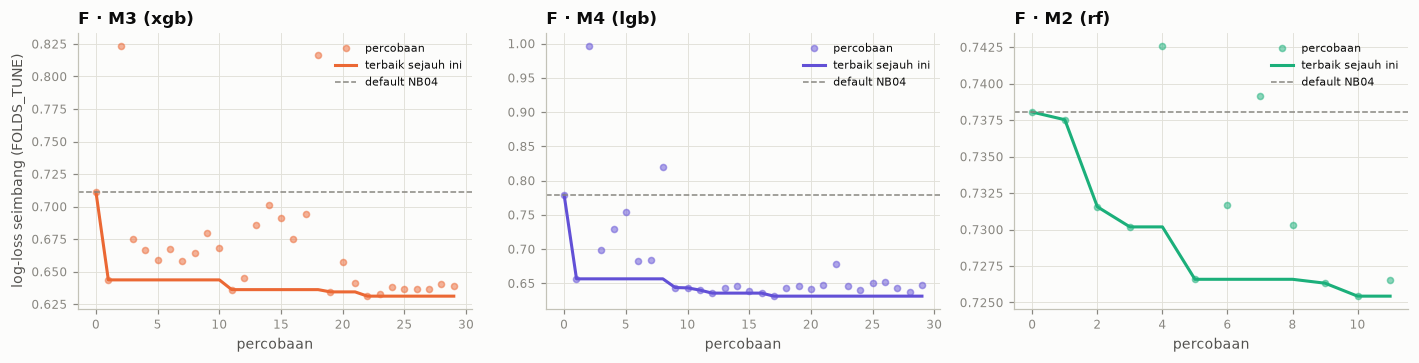

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
for a_, code, col in zip(ax, ['M3', 'M4', 'M2'], [C['s2'], C['s7'], C['s3']]):
    t_ = TRIALS[(TRIALS.model == code) & (TRIALS.state == 'COMPLETE')].sort_values('trial')
    a_.plot(t_.trial, t_.bal_logloss_tune, 'o', color=col, ms=4, alpha=.5, label='percobaan')
    a_.plot(t_.trial, t_.bal_logloss_tune.cummin(), color=col, lw=2, label='terbaik sejauh ini')
    a_.axhline(t_.bal_logloss_tune.iloc[0], color=C['muted'], ls='--', lw=1, label='default NB04')
    a_.set_title(f'F · {code} ({HPO[code]["base"]})'); a_.set_xlabel('percobaan'); a_.legend(fontsize=7)
ax[0].set_ylabel('log-loss seimbang (FOLDS_TUNE)')
fig.tight_layout(); save_fig(fig, 'F1_hpo_history'); plt.show()

## G. Penilaian ulang di fold penilaian (`FOLDS_EVAL`)
Semua kandidat dinilai di fold yang tidak dipakai untuk memilih. Kolom `bal_logloss_tune` vs `bal_logloss` (eval) memperlihatkan seberapa optimistis skor di fold tuning.

In [11]:
TREE_SPECS = {f'{c}_t': spec(HPO[c]['base'], CORE, HPO[c]['params']) for c in ['M2', 'M3', 'M4']}
SPECS = {**BASE_SPECS, **LR_SPECS, **TREE_SPECS}
t0 = time.time()
for name, s in SPECS.items():
    if name not in EVAL_OOF: EVAL_OOF[name], _ = oof(s)
tune_loss = {**{n: best_lr.loc['lengkap' if n == 'M1_EN' else 'dipangkas', 'bal_logloss_tune'] for n in ['M1_EN', 'M1_P']},
             **{f'{c}_t': HPO[c]['bal_logloss_tune'] for c in ['M2', 'M3', 'M4']}}
for n in SPECS:                                       # model yang belum punya skor fold tuning (baseline, M1_PL)
    if n not in tune_loss: tune_loss[n] = oof(SPECS[n], FOLDS_TUNE)[1]
RES = pd.DataFrame({n: summarize(P) for n, P in EVAL_OOF.items()}).T
RES.insert(0, 'bal_logloss_tune', pd.Series(tune_loss)); RES.insert(0, 'n_fitur', [len(SPECS[n]['cols']) for n in RES.index])
RES.to_csv(OUT / 'eval_results_single.csv')
display(RES.round(3)); print(f'penilaian ulang selesai dalam {time.time() - t0:.0f} dtk')

,n_fitur,bal_logloss_tune,bal_logloss,macro_F1,recall_High,presisi_High,AUC_High,Brier,ECE,ECE_High
M1_v0,40,0.696,0.677,0.681,0.771,0.618,0.941,0.356,0.046,0.042
M2_def,40,0.738,0.738,0.646,0.798,0.537,0.934,0.406,0.125,0.098
M3_def,40,0.709,0.714,0.703,0.679,0.679,0.951,0.347,0.081,0.050
M4_def,40,0.777,0.816,0.712,0.670,0.723,0.953,0.357,0.114,0.045
M1_EN,40,0.656,0.649,0.680,0.771,0.587,0.945,0.355,0.035,0.057
M1_P,33,0.654,0.649,0.678,0.771,0.587,0.945,0.357,0.035,0.057
M1_PL,30,0.664,0.661,0.673,0.780,0.582,0.942,0.365,0.032,0.059
M2_t,40,0.725,0.723,0.644,0.771,0.515,0.929,0.397,0.105,0.086
M3_t,40,0.631,0.637,0.707,0.697,0.661,0.952,0.336,0.038,0.025
M4_t,40,0.631,0.640,0.702,0.706,0.664,0.949,0.337,0.023,0.033


penilaian ulang selesai dalam 59 dtk


## H. Bobot kelas vs SMOTE (§5.4)
Untuk LR terbaik dan pohon terbaik (log-loss eval), bandingkan tiga cara menangani kelas High yang hanya ±14%:
- **balanced** — bobot sampel seimbang per kelas (dipakai sejauh ini);
- **none** — tanpa penyeimbangan;
- **SMOTE** — sampel sintetis kelas minoritas, **hanya di data latih setiap fold** (Chawla dkk., 2002).

Kinerja dinilai pada titik operasi yang sama (ambang P(High) untuk recall High 90%) dan setelah kalibrasi lintas-fold, karena SMOTE diduga merusak kalibrasi (van den Goorbergh dkk., 2022).

In [21]:
def high_threshold(y, P, target=TARGET_RECALL):
    ph = np.sort(P[y == 2, 2])[::-1]; return ph[int(np.ceil(target * len(ph))) - 1]
COST = np.array([[0, 1, 2], [3, 0, 1], [10, 5, 0]])        # baris = sebenarnya, kolom = prediksi (§5.4)
def decide(P, t_high):
    """Lapis 3: High bila P(High) ≥ ambang; selain itu Low vs Medium dipilih dengan BIAYA HARAPAN terkecil (matriks §5.4).
    Argmax tidak dipakai karena probabilitas terkalibrasi mengikuti prior (Low dominan) sehingga Medium hampir tidak pernah terpilih."""
    exp_cost = P @ COST                                          # biaya harapan memprediksi Low / Medium / High
    pred = np.where(exp_cost[:, 1] < exp_cost[:, 0], 1, 0); pred[P[:, 2] >= t_high] = 2; return pred
def cost_of(y, pred): return int((np.bincount(3 * y + pred, minlength=9).reshape(3, 3) * COST).sum())

best_lr_name = RES.loc[[n for n in LR_SPECS], 'bal_logloss'].idxmin()
best_tree_name = RES.loc[list(TREE_SPECS), 'bal_logloss'].idxmin()
rows = []; IMB_OOF = {}
for base_name in [best_lr_name, best_tree_name]:
    for wt in ['balanced', 'none', 'smote']:
        s = dict(SPECS[base_name]); s['weighting'] = wt
        P = EVAL_OOF[base_name] if wt == 'balanced' else oof(s)[0]; IMB_OOF[(base_name, wt)] = P
        Q = crossfit_calibrate(P, y_dev, FOLDS_EVAL, 'temperature+prior'); t = high_threshold(y_dev, Q); pred = decide(Q, t)
        rows.append({'model': base_name, 'penyeimbangan': wt, 'macro_F1_argmax': macro_f1(y_dev, P.argmax(1)), 'recall_High_argmax': recall_high(y_dev, P.argmax(1)),
                     'macro_F1_recall90': macro_f1(y_dev, pred), 'flag_High_recall90': int((pred == 2).sum()), 'biaya_recall90': cost_of(y_dev, pred),
                     'AUC_High': roc_auc_score(y_dev == 2, P[:, 2]), 'Brier_mentah': brier(y_dev, P), 'ECE_High_mentah': ece(y_dev, P, cls=2),
                     'Brier_kalibrasi': brier(y_dev, Q), 'ECE_High_kalibrasi': ece(y_dev, Q, cls=2)})
IMB = pd.DataFrame(rows); IMB.to_csv(OUT / 'imbalance_comparison.csv', index=False)
display(IMB.round(3))
# aturan pilih: SMOTE hanya dipakai bila macro-F1 di titik operasi naik ≥ 0,01 DAN Brier terkalibrasi tidak memburuk
WEIGHTING = {}
for base_name in [best_lr_name, best_tree_name]:
    d_ = IMB[IMB.model == base_name].set_index('penyeimbangan')
    better = (d_.loc['smote', 'macro_F1_recall90'] >= d_.loc['balanced', 'macro_F1_recall90'] + 0.01) and (d_.loc['smote', 'Brier_kalibrasi'] <= d_.loc['balanced', 'Brier_kalibrasi'])
    WEIGHTING[base_name] = 'smote' if better else 'balanced'
    print(f'{base_name}: dipilih "{WEIGHTING[base_name]}"', '' if better else '(SMOTE tidak memenuhi syarat: F1 naik ≥ 0,01 dan Brier terkalibrasi tidak memburuk)')
for n, wt in WEIGHTING.items():
    if wt != 'balanced':
        SPECS[n] = {**SPECS[n], 'weighting': wt}; EVAL_OOF[n] = IMB_OOF[(n, wt)]
        if n in LOGIC: LOGIC[n] = logic_test(fit_full(SPECS[n]), SPECS[n]['cols'])      # uji logika ulang untuk versi SMOTE

,model,penyeimbangan,macro_F1_argmax,recall_High_argmax,macro_F1_recall90,flag_High_recall90,biaya_recall90,AUC_High,Brier_mentah,ECE_High_mentah,Brier_kalibrasi,ECE_High_kalibrasi
0,M1_P,balanced,0.677,0.743,0.632,200,369,0.942,0.348,0.043,0.313,0.018
1,M1_P,none,0.699,0.624,0.614,210,382,0.946,0.312,0.031,0.311,0.019
2,M1_P,smote,0.677,0.743,0.632,200,369,0.942,0.348,0.043,0.313,0.018
3,M3_t,balanced,0.707,0.697,0.653,189,359,0.952,0.336,0.025,0.305,0.017
4,M3_t,none,0.708,0.624,0.660,188,352,0.953,0.304,0.027,0.302,0.029
5,M3_t,smote,0.722,0.734,0.607,219,389,0.947,0.326,0.025,0.308,0.021


M1_P: dipilih "balanced" (SMOTE tidak memenuhi syarat: F1 naik ≥ 0,01 dan Brier terkalibrasi tidak memburuk)
M3_t: dipilih "balanced" (SMOTE tidak memenuhi syarat: F1 naik ≥ 0,01 dan Brier terkalibrasi tidak memburuk)


## I. Ensemble (§6)
1. **Keberagaman**: korelasi kesalahan OOF (1 − P(kelas sebenarnya)) antar-model. Korelasi tinggi = ensemble sedikit menolong.
2. **Top-k**: rata-rata probabilitas k model terbaik. Peringkat memakai log-loss **fold tuning**, bukan fold penilaian, supaya pemilihan tidak memakai data penilaian.
3. **Rata-rata berbobot**: bobot ≥ 0, jumlah 1, meminimalkan log-loss seimbang. Bobot di-fit **lintas-fold** (4 fold → fold ke-5) sehingga penilaiannya jujur; komposisi akhir di-fit di semua OOF.

**Syarat anggota**: varian LR yang masuk ensemble harus lolos uji logika. Kalau tidak, ensemble ikut melanggar logika dan pasti gagal kriteria 4 gerbang.

In [22]:
lr_ok = [n for n in LR_SPECS if LOGIC[n].lolos.all()]                 # anggota ensemble wajib lolos uji logika
best_lr_ok = RES.loc[lr_ok, 'bal_logloss'].idxmin() if lr_ok else best_lr_name
POOL = [best_lr_ok] + list(TREE_SPECS)
print(f'LR untuk ensemble: {best_lr_ok} ({"lolos uji logika" if lr_ok else "tidak ada varian LR yang lolos → pakai LR terbaik"})')
ERR = pd.DataFrame({n: 1 - EVAL_OOF[n][np.arange(len(DEV)), y_dev] for n in POOL})
display(ERR.corr(method='spearman').round(2))

rank_tune = pd.Series({n: RES.loc[n, 'bal_logloss_tune'] for n in POOL}).sort_values()
ENS = {}
for k in (2, 3):
    mem = list(rank_tune.index[:k]); ENS[f'ENS_top{k}'] = {'members': mem, 'weights': [1 / k] * k}

def fit_weights(Ps, y):
    def loss(z):
        w = np.exp(z) / np.exp(z).sum(); return bal_logloss(y, sum(wi * P for wi, P in zip(w, Ps)))
    z = minimize(loss, np.zeros(len(Ps)), method='Nelder-Mead', options={'maxiter': 2000, 'xatol': 1e-4, 'fatol': 1e-6}).x
    return np.exp(z) / np.exp(z).sum()
Ps = [EVAL_OOF[n] for n in POOL]; P_w = np.zeros_like(Ps[0])
for tr, va in FOLDS_EVAL:
    w = fit_weights([P[tr] for P in Ps], y_dev[tr]); P_w[va] = sum(wi * P[va] for wi, P in zip(w, Ps))
w_all = fit_weights(Ps, y_dev); ENS['ENS_w'] = {'members': POOL, 'weights': list(w_all)}
for name, e in ENS.items():
    EVAL_OOF[name] = P_w if name == 'ENS_w' else sum(w * EVAL_OOF[m] for w, m in zip(e['weights'], e['members']))
ENS_RES = pd.DataFrame({n: {**summarize(EVAL_OOF[n]), 'komposisi': ', '.join(f'{m} {w:.0%}' for m, w in zip(e['members'], e['weights']))} for n, e in ENS.items()}).T
display(ENS_RES)

LR untuk ensemble: M1_P (tidak ada varian LR yang lolos → pakai LR terbaik)


,M1_P,M2_t,M3_t,M4_t
M1_P,1.00,0.79,0.86,0.84
M2_t,0.79,1.00,0.86,0.86
M3_t,0.86,0.86,1.00,0.97
M4_t,0.84,0.86,0.97,1.00


,bal_logloss,macro_F1,recall_High,presisi_High,AUC_High,Brier,ECE,ECE_High,komposisi
ENS_top2,0.632959,0.712755,0.706422,0.681416,0.95065,0.333565,0.02878,0.02523,"M3_t 50%, M4_t 50%"
ENS_top3,0.618486,0.711768,0.752294,0.656,0.952017,0.326577,0.024588,0.032775,"M3_t 33%, M4_t 33%, M1_P 33%"
ENS_w,0.62463,0.712617,0.752294,0.656,0.950291,0.329161,0.046824,0.032853,"M1_P 34%, M2_t 5%, M3_t 42%, M4_t 19%"


## J. Kalibrasi (lapis 2)
Dua metode dibandingkan lintas-fold (kalibrator di-fit di 4 fold OOF, diterapkan ke fold ke-5):
- **temperature + prior**: satu suhu T + koreksi prior per kelas (3 parameter). Prior perlu dikoreksi karena model dilatih dengan bobot seimbang, sehingga P(High) terdorong naik;
- **isotonic** per kelas (lebih lentur, lebih rawan overfit di data kecil).

Metode terpilih per kandidat = log-loss (tanpa bobot) terendah, karena kalibrasi menyangkut frekuensi sebenarnya.

In [23]:
CANDS = {n: {'members': [n], 'weights': [1.0]} for n in list(LR_SPECS) + list(TREE_SPECS)}; CANDS.update(ENS)
CAL = {}; CAL_METHOD = {}; rows = []
for n in CANDS:
    best_m, best_v = None, np.inf
    for m in CALIBRATORS:
        Q = crossfit_calibrate(EVAL_OOF[n], y_dev, FOLDS_EVAL, m); v = log_loss(y_dev, np.clip(Q, 1e-6, 1), labels=[0, 1, 2])
        rows.append({'kandidat': n, 'kalibrasi': m, 'log_loss': v, 'Brier': brier(y_dev, Q), 'ECE': ece(y_dev, Q), 'ECE_High': ece(y_dev, Q, cls=2)})
        if v < best_v: best_m, best_v = m, v
    CAL_METHOD[n] = best_m; CAL[n] = crossfit_calibrate(EVAL_OOF[n], y_dev, FOLDS_EVAL, best_m)
CALRES = pd.DataFrame(rows); CALRES.to_csv(OUT / 'calibration_comparison.csv', index=False)
display(CALRES.pivot(index='kandidat', columns='kalibrasi', values=['Brier', 'ECE_High']).round(3))
print('metode terpilih:', CAL_METHOD)

Brier                          ECE_High                         
kalibrasi isotonic  tanpa temperature+prior isotonic  tanpa temperature+prior
kandidat                                                                     
ENS_top2     0.319  0.334             0.306    0.022  0.025             0.022
ENS_top3     0.310  0.327             0.299    0.033  0.033             0.022
ENS_w        0.313  0.329             0.302    0.024  0.033             0.018
M1_EN        0.325  0.355             0.314    0.035  0.057             0.027
M1_P         0.328  0.348             0.313    0.039  0.043             0.018
M1_PL        0.341  0.365             0.323    0.044  0.059             0.026
M1_v0        0.326  0.356             0.316    0.033  0.042             0.023
M2_t         0.354  0.397             0.345    0.038  0.086             0.018
M3_t         0.318  0.336             0.305    0.024  0.025             0.017
M4_t         0.319  0.337             0.310    0.025  0.033             0.024

metode terpilih: {'M1_v0': 'temperature+prior', 'M1_EN': 'temperature+prior', 'M1_P': 'temperature+prior', 'M1_PL': 'temperature+prior', 'M2_t': 'temperature+prior', 'M3_t': 'temperature+prior', 'M4_t': 'temperature+prior', 'ENS_top2': 'temperature+prior', 'ENS_top3': 'temperature+prior', 'ENS_w': 'temperature+prior'}


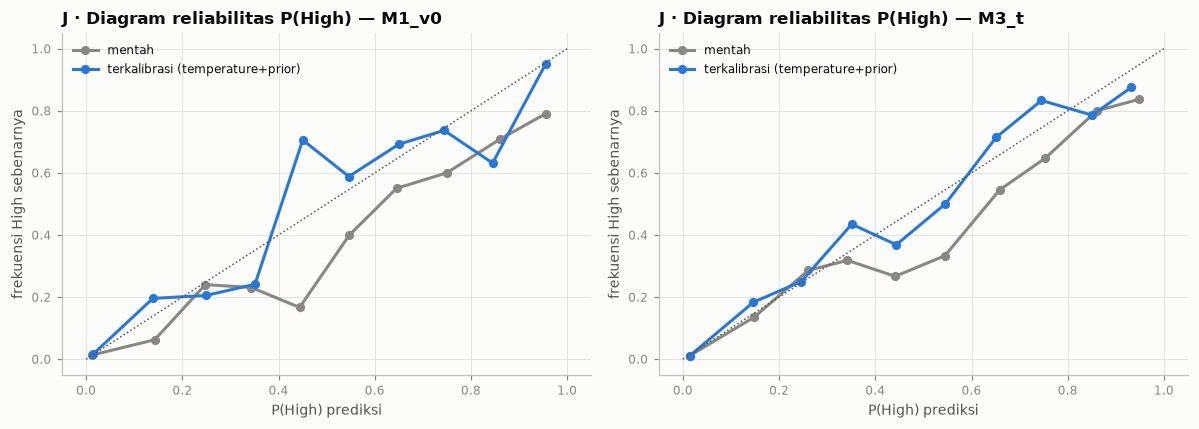

In [24]:
def reliability(ax, y, P, label, col):
    edges = np.linspace(0, 1, 11); b = np.clip(np.digitize(P[:, 2], edges[1:-1]), 0, 9)
    xs = [P[b == i, 2].mean() for i in range(10) if (b == i).sum() >= 5]; ys = [(y[b == i] == 2).mean() for i in range(10) if (b == i).sum() >= 5]
    ax.plot(xs, ys, '-o', color=col, ms=5, label=label)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, n in zip(ax, ['M1_v0', best_tree_name]):
    reliability(a_, y_dev, EVAL_OOF[n], 'mentah', C['muted']); reliability(a_, y_dev, CAL[n], f'terkalibrasi ({CAL_METHOD[n]})', C['s1'])
    a_.plot([0, 1], [0, 1], ls=':', color=C['ink2'], lw=1); a_.set_xlabel('P(High) prediksi'); a_.set_ylabel('frekuensi High sebenarnya')
    a_.set_title(f'J · Diagram reliabilitas P(High) — {n}'); a_.legend()
fig.tight_layout(); save_fig(fig, 'J1_reliability'); plt.show()

## K. Lapis 2–3: conformal, ambang, keputusan Otomatis / Review
Untuk setiap kandidat (probabilitas terkalibrasi lintas-fold):
- **Ambang P(High)** terbesar yang memberi recall High ≥ 90% (gaya Neyman–Pearson);
- **Low vs Medium** dipilih dengan **biaya harapan terkecil** dari matriks §5.4, bukan argmax. Probabilitas terkalibrasi mengikuti prior (Low dominan), jadi argmax hampir tidak pernah memilih Medium;
- **Conformal LAC** α = 10%, tiga varian dibandingkan:
  - global (satu q̂);
  - Mondrian per segmen ukuran (`size_class_reference`, sementara sampai segmen NB08 tersedia);
  - **Mondrian per kelas** (dipakai): cakupan 90% dijamin di setiap kelas. Uji asap menunjukkan versi global hanya menjangkau ±82% kasus High, sedangkan cakupan per segmen sudah ±90% tanpa perlakuan khusus;
- **Otomatis** = himpunan conformal berisi tepat satu kelas yang sama dengan keputusan lapis 3; selain itu **Review analis**.

In [25]:
SEG_DEV = DEV.size_class_reference.values
def decision_block(y, P, seg=None, mode='kelas'):
    """mode: 'global' (satu q̂), 'segmen' (Mondrian per segmen ukuran), 'kelas' (Mondrian per kelas — dipakai)."""
    t = high_threshold(y, P); pred = decide(P, t)
    if mode == 'segmen':
        qd = mondrian_q(y, P, seg, ALPHA); q = np.array([qd[s] for s in seg]); S = sets_from_q(P, q)
    elif mode == 'kelas':
        q = classcond_q(y, P, ALPHA); S = sets_classcond(P, q)
    else:
        q = conformal_q(y, P, ALPHA); S = sets_from_q(P, q)
    auto = (S.sum(1) == 1) & S[np.arange(len(P)), pred]
    return t, q, S, pred, auto

rows = []; DEC = {}
for n in CANDS:
    for mode in ('global', 'segmen', 'kelas'):
        t, q, S, pred, auto = decision_block(y_dev, CAL[n], SEG_DEV, mode)
        cov_seg = {f'cakupan_{s}': S[SEG_DEV == s][np.arange((SEG_DEV == s).sum()), y_dev[SEG_DEV == s]].mean() for s in ['Kecil', 'Menengah', 'Besar']}
        rows.append({'kandidat': n, 'conformal': mode, 'ambang_P_High': t,
                     'macro_F1_keputusan': macro_f1(y_dev, pred), 'recall_High': recall_high(y_dev, pred), 'flag_High': int((pred == 2).sum()),
                     'biaya': cost_of(y_dev, pred), 'cakupan': S[np.arange(len(y_dev)), y_dev].mean(), **cov_seg,
                     **{f'cakupan_{RISK_ORDER[k]}': S[y_dev == k][:, k].mean() for k in range(3)}, 'pct_otomatis': 100 * auto.mean(),
                     'macro_F1_otomatis': macro_f1(y_dev[auto], pred[auto]), 'High_lolos_otomatis': int(((y_dev == 2) & auto & (pred != 2)).sum())})
        if mode == 'kelas': DEC[n] = (t, q, S, pred, auto)
L23 = pd.DataFrame(rows); L23.to_csv(OUT / 'layer23_oof.csv', index=False)
display(L23[L23.conformal == 'kelas'].drop(columns='conformal').set_index('kandidat').round(3))
print('Perbandingan tiga cara conformal untuk champion NB04 (cakupan per segmen & per kelas):')
display(L23[L23.kandidat == 'M1_v0'].set_index('conformal')[['cakupan', 'cakupan_Kecil', 'cakupan_Menengah', 'cakupan_Besar', 'cakupan_Low', 'cakupan_Medium', 'cakupan_High', 'pct_otomatis']].round(3))

,ambang_P_High,macro_F1_keputusan,recall_High,flag_High,biaya,cakupan,cakupan_Kecil,cakupan_Menengah,cakupan_Besar,cakupan_Low,cakupan_Medium,cakupan_High,pct_otomatis,macro_F1_otomatis,High_lolos_otomatis
kandidat,,,,,,,,,,,,,,,
M1_v0,0.116,0.612,0.908,206,389,0.908,0.917,0.909,0.896,0.904,0.910,0.917,50.000,0.795,7
M1_EN,0.118,0.598,0.908,219,395,0.908,0.917,0.909,0.896,0.904,0.910,0.917,51.000,0.819,6
M1_P,0.121,0.632,0.908,200,369,0.906,0.898,0.919,0.891,0.904,0.905,0.917,48.750,0.797,7
M1_PL,0.095,0.575,0.908,235,419,0.906,0.912,0.903,0.905,0.904,0.910,0.908,47.750,0.790,7
M2_t,0.125,0.552,0.908,246,459,0.906,0.898,0.906,0.915,0.904,0.910,0.908,38.875,0.698,7
M3_t,0.148,0.653,0.908,189,359,0.908,0.894,0.911,0.915,0.904,0.910,0.917,51.875,0.802,8
M4_t,0.142,0.647,0.908,201,354,0.906,0.894,0.903,0.925,0.904,0.910,0.908,51.500,0.795,9
ENS_top2,0.153,0.651,0.908,191,356,0.905,0.889,0.909,0.915,0.904,0.905,0.908,53.125,0.795,9
ENS_top3,0.130,0.649,0.908,197,356,0.906,0.898,0.909,0.910,0.904,0.910,0.908,53.625,0.813,9


Perbandingan tiga cara conformal untuk champion NB04 (cakupan per segmen & per kelas):


,cakupan,cakupan_Kecil,cakupan_Menengah,cakupan_Besar,cakupan_Low,cakupan_Medium,cakupan_High,pct_otomatis
conformal,,,,,,,,
global,0.902,0.917,0.885,0.920,0.990,0.735,0.817,55.75
segmen,0.909,0.912,0.906,0.910,0.988,0.760,0.826,55.25
kelas,0.908,0.917,0.909,0.896,0.904,0.910,0.917,50.00


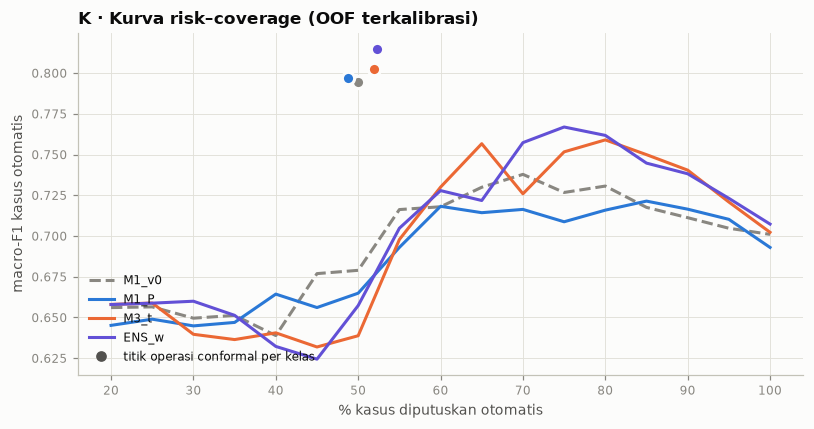

In [26]:
COV = np.linspace(.2, 1, 17)
def risk_coverage(y, P):
    o = np.argsort(-P.max(1)); return np.array([macro_f1(y[o[:int(round(c * len(y)))]], P[o[:int(round(c * len(y)))]].argmax(1)) for c in COV])
show = ['M1_v0', best_lr_name, best_tree_name, 'ENS_w']; show = list(dict.fromkeys(show))
fig, ax = plt.subplots(figsize=(7.5, 4))
for n, col in zip(show, [C['muted'], C['s1'], C['s2'], C['s7']]):
    ax.plot(100 * COV, risk_coverage(y_dev, CAL[n]), color=col, lw=2, ls='--' if n == 'M1_v0' else '-', label=n)
    r = L23[(L23.kandidat == n) & (L23.conformal == 'kelas')].iloc[0]
    ax.plot(r.pct_otomatis, r.macro_F1_otomatis, 'o', color=col, ms=8, mec=C['surface'], mew=2)
ax.set_xlabel('% kasus diputuskan otomatis'); ax.set_ylabel('macro-F1 kasus otomatis'); ax.set_title('K · Kurva risk–coverage (OOF terkalibrasi)')
ax.plot([], [], 'o', color=C['ink2'], label='titik operasi conformal per kelas'); ax.legend(loc='lower left')
fig.tight_layout(); save_fig(fig, 'K1_risk_coverage'); plt.show()

## L. Gerbang promosi (lapis 4)
Di NB05 setiap kandidat sudah dibungkus lapis 2–3 yang sama, jadi **K1 dinilai pada keputusan operasional** (ambang recall High 90% + Low/Medium dengan biaya harapan, di probabilitas terkalibrasi), bukan argmax. Perbandingan pada recall High yang sama lebih adil.

| # | Kriteria | Jalur **tantangan** (model baru) | Jalur **perbaikan champion** (varian LR) |
|---|---|---|---|
| 1 | macro-F1 keputusan | lebih tinggi **dan** signifikan (bootstrap berpasangan, p < 0,05) | **tidak lebih buruk**: batas bawah 95% selisih ≥ −0,03 (*non-inferiority*) |
| 2 | recall High argmax | ≥ champion − 0,02 | ≥ champion − 0,02 |
| 3 | Brier terkalibrasi | ≤ champion | ≤ champion + 0,005 |
| 4 | uji logika | 100% lolos | 100% lolos |

**Jalur perbaikan** (usulan baru, perlu disepakati tim): champion yang melanggar logika bisnis boleh diganti versi LR-nya sendiri yang patuh logika, asal kinerjanya tidak lebih buruk. Tanpa jalur ini, gerbang justru mempertahankan model yang tidak bisa dibela di depan risk committee. Informasi tambahan: *corrected resampled t-test* (Nadeau & Bengio, 2003) atas selisih per fold.

**Bila beberapa challenger lolos**, pemenangnya = log-loss seimbang OOF terendah (skor *proper*, lebih stabil daripada selisih F1 yang berisik); bila seri, yang anggotanya lebih sedikit.

In [27]:
FINAL_CORE = {n: fit_full(SPECS[n]) for n in set(m for c in CANDS.values() for m in c['members'])}
def cand_model(n, finals=FINAL_CORE):
    c = CANDS[n]; ms = [finals[m] for m in c['members']]
    return ms[0] if len(ms) == 1 else EnsembleModel(ms, c['weights'])
for n in CANDS:
    if n not in LOGIC: LOGIC[n] = logic_test(cand_model(n), sorted(set(sum([SPECS[m]['cols'] for m in CANDS[n]['members']], []))))
LOGIC_ALL = pd.concat([t.assign(kandidat=n) for n, t in LOGIC.items()]); LOGIC_ALL.to_csv(OUT / 'logic_test.csv', index=False)

def gate_row(champ, chal, path):
    yc, yh = DEC[champ][3], DEC[chal][3]
    m_, lo, hi, p = boot_diff(macro_f1, yc, yh)
    fd = np.array([macro_f1(y_dev[va], yh[va]) - macro_f1(y_dev[va], yc[va]) for _, va in FOLDS_EVAL])
    t_nb = fd.mean() / np.sqrt((1 / len(fd) + 1 / 4) * fd.var(ddof=1) + 1e-12); p_nb = 1 - stats.t.cdf(t_nb, df=len(fd) - 1)
    rc, rh = recall_high(y_dev, EVAL_OOF[champ].argmax(1)), recall_high(y_dev, EVAL_OOF[chal].argmax(1))
    bc, bh = brier(y_dev, CAL[champ]), brier(y_dev, CAL[chal])
    k1 = (m_ > 0 and p < 0.05) if path == 'tantangan' else (lo >= -NONINF_MARGIN)
    k2 = rh >= rc - 0.02; k3 = bh <= bc + (0.005 if path == 'perbaikan' else 0); k4 = bool(LOGIC[chal].lolos.all())
    return {'champion': champ, 'kandidat': chal, 'jalur': path, 'ΔF1': m_, 'ΔF1_lo95': lo, 'ΔF1_hi95': hi, 'p_bootstrap': p, 'p_NadeauBengio': p_nb,
            'K1': k1, 'recall_High_argmax': rh, 'K2': k2, 'Brier': bh, 'K3': k3, 'K4_logika': k4, 'pct_otomatis': 100 * DEC[chal][4].mean(),
            'lolos': bool(k1 and k2 and k3 and k4)}

CHAMP = 'M1_v0'; gate_rows = []
# langkah 1 — perbaikan champion
fix = [gate_row(CHAMP, n, 'perbaikan') for n in LR_SPECS if n != 'M1_v0']; gate_rows += fix
ok_fix = [r['kandidat'] for r in fix if r['lolos']]
if ok_fix:
    CHAMP = min(ok_fix, key=lambda n: RES.loc[n, 'bal_logloss']); print(f'langkah 1: champion diperbaiki → {CHAMP}')
else:
    print('langkah 1: tidak ada varian LR yang lolos jalur perbaikan; M1_v0 tetap')
# langkah 2 — tantangan
chal = [gate_row(CHAMP, n, 'tantangan') for n in CANDS if n not in LR_SPECS]; gate_rows += chal
ok_chal = [r for r in chal if r['lolos']]
if ok_chal:
    # di antara yang lolos: log-loss seimbang terendah (skor proper, lebih stabil daripada selisih F1); seri → anggota lebih sedikit
    CHAMP = min((r['kandidat'] for r in ok_chal), key=lambda n: (round(bal_logloss(y_dev, EVAL_OOF[n]), 3), len(CANDS[n]['members'])))
    print(f'langkah 2: {len(ok_chal)} challenger lolos ({", ".join(r["kandidat"] for r in ok_chal)}) → champion baru {CHAMP} (log-loss seimbang terendah)')
else:
    print(f'langkah 2: tidak ada challenger yang lolos; champion = {CHAMP}')
GATE = pd.DataFrame(gate_rows); GATE.to_csv(OUT / 'promotion_gate.csv', index=False)
card = GATE[['jalur', 'champion', 'kandidat', 'ΔF1', 'ΔF1_lo95', 'p_bootstrap', 'p_NadeauBengio', 'K1', 'K2', 'K3', 'K4_logika', 'lolos']].copy()
for c in ['K1', 'K2', 'K3', 'K4_logika', 'lolos']: card[c] = card[c].map({True: '✅', False: '❌'})
display(card.round(3))

langkah 1: tidak ada varian LR yang lolos jalur perbaikan; M1_v0 tetap
langkah 2: tidak ada challenger yang lolos; champion = M1_v0


,jalur,champion,kandidat,ΔF1,ΔF1_lo95,p_bootstrap,p_NadeauBengio,K1,K2,K3,K4_logika,lolos
0,perbaikan,M1_v0,M1_EN,-0.013,-0.030,0.930,0.916,❌,✅,✅,❌,❌
1,perbaikan,M1_v0,M1_P,0.020,-0.000,0.028,0.045,✅,❌,✅,❌,❌
2,perbaikan,M1_v0,M1_PL,-0.037,-0.061,0.999,0.975,❌,✅,❌,❌,❌
3,tantangan,M1_v0,M2_t,-0.061,-0.094,1.000,0.950,❌,✅,❌,✅,❌
4,tantangan,M1_v0,M3_t,0.041,0.009,0.005,0.081,✅,❌,✅,✅,❌
5,tantangan,M1_v0,M4_t,0.035,0.002,0.018,0.082,✅,❌,✅,✅,❌
6,tantangan,M1_v0,ENS_top2,0.039,0.007,0.011,0.038,✅,❌,✅,✅,❌
7,tantangan,M1_v0,ENS_top3,0.037,0.010,0.005,0.056,✅,✅,✅,❌,❌
8,tantangan,M1_v0,ENS_w,0.025,-0.001,0.030,0.190,✅,✅,✅,❌,❌


## M. Nasabah non-kredit & prospect (§5.6)
Champion yang sama dilatih ulang dengan set fitur populasinya.
- **Non-kredit**: `set_noncredit` (tanpa `utilization`, `log_limit`); conformal Mondrian per segmen.
- **Prospect**: `set_prospect` + **importance weighting** (Shimodaira, 2000):
  1. classifier nasabah dev vs prospect di fitur portabel (prediksi lintas-fold) → p(prospect | x);
  2. bobot baris latih w = (p / (1 − p) × n_dev / n_prospect)^0,5, dipotong ke [0,1; 10]. Bobot **diratakan** (pangkat 0,5, gaya Shimodaira) karena bobot mentah terlalu ekstrem untuk 800 baris: di uji asap, ESS hanya ±35% dan ambang P(High) runtuh;
  3. model dilatih dengan bobot kelas × w; ambang P(High) tetap dari recall High 90% pada nasabah dev (tanpa bobot);
  4. ketidakpastian: **weighted conformal** (Tibshirani dkk., 2019) — q̂ berbeda per prospect.
- Varian tanpa bobot ikut dihitung sebagai pembanding. Mana yang lebih tepat untuk prospect baru bisa dinilai di NB06 terhadap GT.
- Label prospect (GT) **tidak** dibaca di sini; evaluasinya di NB06.

In [28]:
def adapt(s, set_name):
    return {**s, 'cols': [c for c in s['cols'] if c in FEATURE_SETS[set_name]]}
def cand_oof(n, set_name, sample_weight=None):
    c = CANDS[n]; return sum(w * oof(adapt(SPECS[m], set_name), sample_weight=sample_weight)[0] for w, m in zip(c['weights'], c['members']))
def cand_fit(n, set_name, sample_weight=None):
    c = CANDS[n]; ms = [fit_full(adapt(SPECS[m], set_name), sample_weight=sample_weight) for m in c['members']]
    return ms[0] if len(ms) == 1 else EnsembleModel(ms, c['weights'])
def high_threshold_w(y, P, w, target=TARGET_RECALL):
    ix = np.flatnonzero(y == 2); o = ix[np.argsort(-P[ix, 2])]; cw = np.cumsum(w[o]) / w[o].sum()
    return P[o[min(np.searchsorted(cw, target), len(o) - 1)], 2]

# importance weighting
PROS = SCORE_POP[SCORE_POP.feature_set == 'set_prospect'].reset_index(drop=True)
DOM_X = pd.concat([DEV, PROS], ignore_index=True); DOM_y = np.r_[np.zeros(len(DEV)), np.ones(len(PROS))].astype(int)
dom = lambda: make_pipeline(make_prep(FEATURE_SETS['set_prospect']), SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                            StandardScaler(), LogisticRegression(C=0.3, max_iter=5000))
p_dom = np.zeros(len(DOM_X))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(DOM_X, DOM_y):
    p_dom[va] = dom().fit(DOM_X.iloc[tr], DOM_y[tr]).predict_proba(DOM_X.iloc[va])[:, 1]
ratio = len(DEV) / len(PROS)
IW_POWER, IW_CLIP = 0.5, (0.1, 10.0)          # bobot diratakan (pangkat 0,5) & dipotong: bobot mentah terlalu ekstrem untuk 800 baris
def iw(p): return np.clip((p / (1 - p) * ratio) ** IW_POWER, *IW_CLIP)
W_ALL = iw(p_dom); W_DEV, W_PROS = W_ALL[:len(DEV)], W_ALL[len(DEV):]
W_RAW = np.clip(p_dom[:len(DEV)] / (1 - p_dom[:len(DEV)]) * ratio, 0.05, 20)
print(f'ESS bobot mentah (tanpa perataan): {W_RAW.sum() ** 2 / (W_RAW ** 2).sum() / len(DEV):.0%}')
ESS = W_DEV.sum() ** 2 / (W_DEV ** 2).sum() / len(DEV)
DOMAIN_MODEL = dom().fit(DOM_X, DOM_y)
print(f'C2ST nasabah vs prospect (fitur portabel): AUC {roc_auc_score(DOM_y, p_dom):.3f} | ESS bobot {ESS:.0%} dari 800 | bobot dev median {np.median(W_DEV):.2f}, maks {W_DEV.max():.1f}')

POPS = {}
t0 = time.time()
for set_name, sw in [('set_noncredit', None), ('set_prospect', None), ('set_prospect_IW', W_DEV)]:
    base_set = 'set_prospect' if set_name.startswith('set_prospect') else set_name
    P = cand_oof(CHAMP, base_set, sw); cal = CALIBRATORS[CAL_METHOD[CHAMP]]().fit(P, y_dev)
    Q = crossfit_calibrate(P, y_dev, FOLDS_EVAL, CAL_METHOD[CHAMP])
    POPS[set_name] = {'oof_cal': Q, 'calibrator': cal, 'model': cand_fit(CHAMP, base_set, sw), 'sw': sw,
                      't_high': high_threshold(y_dev, Q)}          # ambang: recall High 90% pada nasabah dev (tanpa bobot)
    print(f'{set_name}: OOF macro-F1 argmax {macro_f1(y_dev, P.argmax(1)):.3f}, bal_logloss {bal_logloss(y_dev, P):.3f}, ambang P(High) {POPS[set_name]["t_high"]:.3f}')
print(f'selesai dalam {time.time() - t0:.0f} dtk')

# perbandingan pada 600 prospect (tanpa label)
rows = []
v0 = pd.read_csv(V0_SCORES) if V0_SCORES.exists() else None          # arsip v0 (dibuat di sel path)
if v0 is not None:
    v0p = v0.set_index('company_id').reindex(PROS.company_id)
    rows.append({'versi': 'v0 NB04 (tanpa kalibrasi, tanpa bobot)', '% High': 100 * (v0p.pred_class == 'High').mean(), 'rata2_P_High': v0p.p_high.mean()})
for set_name in ['set_prospect', 'set_prospect_IW']:
    Pp = POPS[set_name]['calibrator'].transform(POPS[set_name]['model'].predict_proba(PROS)); pred = decide(Pp, POPS[set_name]['t_high'])
    rows.append({'versi': f'v1 {set_name} (terkalibrasi)', '% High': 100 * (pred == 2).mean(), 'rata2_P_High': Pp[:, 2].mean()})
PROS_CMP = pd.DataFrame(rows); PROS_CMP.to_csv(OUT / 'prospect_shift_comparison.csv', index=False); display(PROS_CMP.round(3))
print(f'acuan: proporsi High di label nasabah dev {np.mean(y_dev == 2):.1%}')

ESS bobot mentah (tanpa perataan): 35%
C2ST nasabah vs prospect (fitur portabel): AUC 0.792 | ESS bobot 70% dari 800 | bobot dev median 0.71, maks 10.0
set_noncredit: OOF macro-F1 argmax 0.672, bal_logloss 0.677, ambang P(High) 0.103
set_prospect: OOF macro-F1 argmax 0.639, bal_logloss 0.729, ambang P(High) 0.099
set_prospect_IW: OOF macro-F1 argmax 0.644, bal_logloss 0.732, ambang P(High) 0.096
selesai dalam 2 dtk


,versi,% High,rata2_P_High
0,"v0 NB04 (tanpa kalibrasi, tanpa bobot)",60.500,0.438
1,v1 set_prospect (terkalibrasi),56.500,0.376
2,v1 set_prospect_IW (terkalibrasi),55.667,0.367


acuan: proporsi High di label nasabah dev 13.6%


## N. Penjelasan model
### N1. Permutation importance per kelompok fitur (lintas-fold)
Seluruh kolom satu kelompok diacak bersama di fold validasi (5 ulangan), lalu kenaikan log-loss seimbang dicatat. Mengacak per kelompok menghindari importance yang "terbagi" di antara fitur yang saling berkorelasi. Rasio relatif-peer ikut teracak karena dihitung ulang dari rasio mentah.

In [29]:
GROUP_MAP = {}
for g, cols in fs['groups'].items():
    gg = {'keuangan mentah': 'keuangan', 'keuangan relatif-peer': 'keuangan', 'missing & tren': 'laporan', 'jaringan & geografi': 'jaringan', 'konsentrasi': 'konsentrasi pembeli'}.get(g, g)
    for c in cols: GROUP_MAP[c] = gg
champ_cols = sorted(set(sum([SPECS[m]['cols'] for m in CANDS[CHAMP]['members']], [])))
GROUPS_USED = {}
for c in champ_cols:
    if c in PZ_OUT: continue
    GROUPS_USED.setdefault(GROUP_MAP.get(c, 'lainnya'), []).append(c)
rng_p = np.random.default_rng(SEED); rows = []
for k, (tr, va) in enumerate(FOLDS_EVAL):
    c = CANDS[CHAMP]; ms = [build(SPECS[m]).fit(DEV.iloc[tr], y_dev[tr]) for m in c['members']]
    mdl = ms[0] if len(ms) == 1 else EnsembleModel(ms, c['weights'])
    Xv = DEV.iloc[va].reset_index(drop=True); base = bal_logloss(y_dev[va], mdl.predict_proba(Xv))
    for g, cols in GROUPS_USED.items():
        for r in range(5):
            Xp = Xv.copy(); perm = rng_p.permutation(len(Xv)); Xp[cols] = Xv[cols].values[perm]
            rows.append({'fold': k, 'kelompok': g, 'n_fitur': len(cols), 'delta_logloss': bal_logloss(y_dev[va], mdl.predict_proba(Xp)) - base})
PIMP = pd.DataFrame(rows).groupby(['kelompok', 'n_fitur']).delta_logloss.agg(['mean', 'std']).reset_index().sort_values('mean', ascending=False)
PIMP.to_csv(OUT / 'permutation_importance_groups.csv', index=False); display(PIMP.round(4))

,kelompok,n_fitur,mean,std
3,keuangan,4,0.7174,0.1677
7,timing bayar,8,0.2245,0.0600
4,konsentrasi pembeli,1,0.1045,0.0371
6,profil,11,0.0947,0.0621
1,fasilitas,2,0.0465,0.0464
0,arus kas,7,0.0451,0.0422
5,laporan,2,0.0026,0.0082
2,jaringan,1,-0.0060,0.0094


### N2. Kontribusi per fitur (SHAP) untuk alasan RM
- Champion LR tunggal → **Linear SHAP eksak** (Lundberg & Lee, 2017): φ = (β_k − rata-rata β) × (z − z̄), dalam satuan log-odds; kolom relatif-peer dan indikator kosong dikembalikan ke fitur asalnya.
- Champion pohon tunggal + `shap` terpasang → **TreeSHAP** pada model biner ordinal (P(>Medium) untuk High, P(>Low) untuk Low/Medium).
- Ensemble / tanpa `shap` → **atribusi oklusi** (fitur diganti median dev; satuan poin probabilitas).

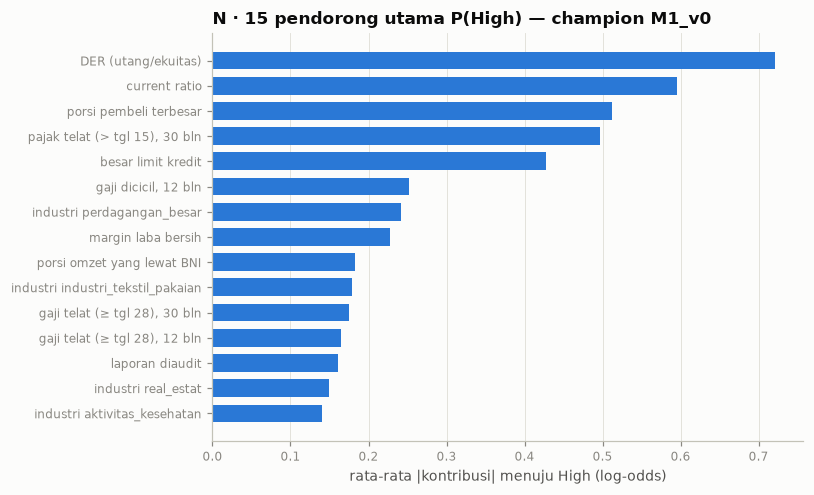

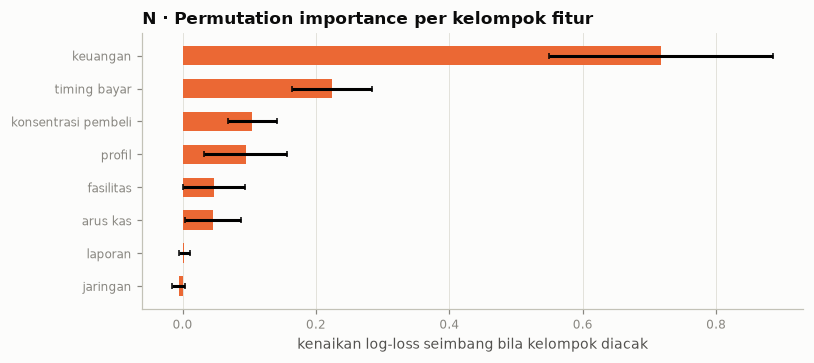

In [30]:
PZ_TO_RAW = {PeerZScaler.out_name(c): c for c in RATIO_COLS}
MED = DEV[CORE].median()
def base_name(n): n = n.replace('missingindicator_', ''); return PZ_TO_RAW.get(n, n)

def contributions(model, X, cls):
    """Matriks kontribusi (n × fitur input) menuju kelas cls[i] per baris, beserta satuannya."""
    cls = np.asarray(cls)
    if isinstance(model, RiskModel) and model.kind == 'lr':
        imp, sc, lr = model.est_.steps[0][1], model.est_.steps[1][1], model.est_.steps[2][1]
        def Z_of(X_): return sc.transform(imp.transform(model.transform_features(X_)))
        names = [base_name(n) for n in imp.get_feature_names_out()]
        Z = Z_of(X); Zbar = Z_of(DEV).mean(0); B = lr.coef_ - lr.coef_.mean(0)
        phi = B[cls] * (Z - Zbar)
        out = pd.DataFrame(phi, columns=names).T.groupby(level=0).sum().T; return out, 'log-odds'
    if isinstance(model, RiskModel) and HAS_SHAP and model.kind in ('xgb', 'lgb', 'rf'):
        Xt = model.transform_features(X); est = model.est_
        Xf = est.imp_.transform(Xt) if getattr(est, 'imp_', None) is not None else Xt.to_numpy(float)
        out = np.zeros(Xf.shape)
        for j, sign in [(0, None), (1, None)]:
            sv = shap.TreeExplainer(est.models_[j]).shap_values(Xf)
            sv = sv[-1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)
            if j == 1: out[cls == 2] = sv[cls == 2]
            else: out[cls == 0] = -sv[cls == 0]; out[cls == 1] = sv[cls == 1]
        names = [base_name(n) for n in Xt.columns]
        return pd.DataFrame(out, columns=names).T.groupby(level=0).sum().T, 'log-odds (TreeSHAP)'
    feats = [c for c in sorted(set(sum([SPECS[m]['cols'] for m in CANDS[CHAMP]['members']], []))) if c not in PZ_OUT]
    P = model.predict_proba(X); r = np.arange(len(X)); out = {}
    for f in feats:
        X1 = X.copy(); X1[f] = MED.get(f, np.nan); out[f] = P[r, cls] - model.predict_proba(X1)[r, cls]
    return pd.DataFrame(out), 'poin probabilitas (oklusi)'

def reason_texts(X, contrib, cls, unit, top=3):
    res = []
    for i in range(len(X)):
        row = contrib.iloc[i]; row = row[row > (0.01 if 'poin' in unit else 0.05)].sort_values(ascending=False).head(top); rs = []
        for f, v in row.items():
            x = X[f].iloc[i] if f in X else np.nan
            if f.startswith('ind_'):
                if x != 1: continue
                txt = f'industri {f[4:].replace("_", " ")}'
            elif f == 'has_report': txt = 'laporan keuangan FY2025 tidak diserahkan' if x == 0 else 'laporan keuangan diserahkan'
            elif f == 'is_audited': txt = 'laporan tidak diaudit' if x == 0 else 'laporan diaudit'
            elif pd.isna(x): txt = f'{LABEL.get(f, f)} tidak tersedia'
            else:
                pct = f in ('pay_late_6m', 'pay_late_12m', 'pay_late_30m', 'tax_late_6m', 'tax_late_12m', 'tax_late_30m', 'pay_split_12m', 'utilization', 'top_buyer_share', 'capture_ratio', 'exp_shocked_anchor')
                fmt = (lambda z: f'{100 * z:.0f}%') if pct else (lambda z: f'{z:.2f}')
                txt = f'{LABEL.get(f, f)} {"tinggi" if x > MED.get(f, x) else "rendah"} ({fmt(x)}; median {fmt(MED.get(f, x))})'
            rs.append(f'{txt} → mendorong {RISK_ORDER[cls[i]]} (+{v:.2f} {unit.split(" ")[0]})' if 'poin' not in unit else f'{txt} → +{100 * v:.0f} poin P({RISK_ORDER[cls[i]]})')
        res.append(rs + [''] * (top - len(rs)))
    return res

champ_final = cand_model(CHAMP)
CON_H, UNIT = contributions(champ_final, DEV, np.full(len(DEV), 2))
glob = CON_H.abs().mean().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(range(len(glob))[::-1], glob.values, color=C['s1'], height=.7)
ax.set_yticks(range(len(glob))[::-1]); ax.set_yticklabels([LABEL.get(f, f.replace('ind_', 'industri ')) for f in glob.index], fontsize=8)
ax.set_xlabel(f'rata-rata |kontribusi| menuju High ({UNIT})'); ax.set_title(f'N · 15 pendorong utama P(High) — champion {CHAMP}'); ax.grid(axis='y', visible=False)
fig.tight_layout(); save_fig(fig, 'N1_global_importance'); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(range(len(PIMP))[::-1], PIMP['mean'], xerr=PIMP['std'], color=C['s2'], height=.6, capsize=2)
ax.set_yticks(range(len(PIMP))[::-1]); ax.set_yticklabels(PIMP.kelompok); ax.set_xlabel('kenaikan log-loss seimbang bila kelompok diacak')
ax.set_title('N · Permutation importance per kelompok fitur'); ax.grid(axis='y', visible=False)
fig.tight_layout(); save_fig(fig, 'N2_permutation_groups'); plt.show()

## O. Model final & skor v1 untuk dashboard
| Populasi | Probabilitas | Ambang P(High) | Conformal |
|---|---|---|---|
| dev (800) | **OOF terkalibrasi lintas-fold** | dari OOF set_core | Mondrian per kelas |
| test (200) | model final set_core + kalibrator (tidak dinilai di sini) | dari OOF set_core | Mondrian per kelas |
| non-kredit (400) | model final set_noncredit + kalibrator | dari OOF set_noncredit | Mondrian per kelas |
| prospect (600) | model final set_prospect **berbobot** + kalibrator | dari OOF set_prospect berbobot | **weighted conformal** per prospect |

Keputusan Low vs Medium memakai biaya harapan (bagian K).

In [31]:
t0 = time.time()
# kalibrator & aturan set_core dari OOF champion
CAL_CORE = CALIBRATORS[CAL_METHOD[CHAMP]]().fit(EVAL_OOF[CHAMP], y_dev)
FINAL_SETS = {'set_core': CalibratedModel(champ_final, CAL_CORE, f'{CHAMP}-v1-NB05 set_core'),
              'set_noncredit': CalibratedModel(POPS['set_noncredit']['model'], POPS['set_noncredit']['calibrator'], f'{CHAMP}-v1-NB05 set_noncredit'),
              'set_prospect': CalibratedModel(POPS['set_prospect_IW']['model'], POPS['set_prospect_IW']['calibrator'], f'{CHAMP}-v1-NB05 set_prospect (IW)')}
RULES = {'set_core': {'t_high': DEC[CHAMP][0], 'q_kelas': classcond_q(y_dev, CAL[CHAMP], ALPHA), 'oof': CAL[CHAMP]},
         'set_noncredit': {'t_high': POPS['set_noncredit']['t_high'], 'q_kelas': classcond_q(y_dev, POPS['set_noncredit']['oof_cal'], ALPHA), 'oof': POPS['set_noncredit']['oof_cal']},
         'set_prospect': {'t_high': POPS['set_prospect_IW']['t_high'], 'oof': POPS['set_prospect_IW']['oof_cal']}}

parts = []
def score_block(X, P, set_name, src):
    seg = X.size_class_reference.values; t = RULES[set_name]['t_high']; pred = decide(P, t)
    if set_name == 'set_prospect':
        s_cal = 1 - RULES['set_prospect']['oof'][np.arange(len(DEV)), y_dev]
        w_test = iw(DOMAIN_MODEL.predict_proba(X)[:, 1])
        q = weighted_conformal_q(s_cal, W_DEV, w_test, ALPHA); method = 'weighted conformal'; S = sets_from_q(P, q)
    else:
        S = sets_classcond(P, RULES[set_name]['q_kelas']); method = 'Mondrian per kelas'
    auto = (S.sum(1) == 1) & S[np.arange(len(P)), pred]
    model = FINAL_SETS[set_name].model; con, unit = contributions(model, X, pred); reasons = reason_texts(X.reset_index(drop=True), con, pred, unit)
    return pd.DataFrame({'company_id': X.company_id.values, 'split': X.split.values, 'customer_type': X.customer_type.values, 'segment_ref': seg,
                         'pred_source': src, 'model_version': f'{CHAMP}-v1-NB05', 'feature_set': set_name,
                         'p_low': P[:, 0].round(4), 'p_medium': P[:, 1].round(4), 'p_high': P[:, 2].round(4),
                         'pred_class': [RISK_ORDER[k] for k in pred],
                         'conformal_set': ['{' + ','.join(RISK_ORDER[k] for k in range(3) if s_[k]) + '}' for s_ in S], 'conformal_method': method,
                         'decision': np.where(auto, 'Otomatis', 'Review analis'),
                         'reason_1': [r[0] for r in reasons], 'reason_2': [r[1] for r in reasons], 'reason_3': [r[2] for r in reasons], 'reason_unit': unit})
parts.append(score_block(DEV, CAL[CHAMP], 'set_core', 'oof'))
for set_name in FEATURE_SETS:
    X = SCORE_POP[SCORE_POP.feature_set == set_name].reset_index(drop=True)
    if len(X): parts.append(score_block(X, FINAL_SETS[set_name].predict_proba(X), set_name, np.where(X.split == 'test', 'test', 'unlabeled')))
RISK_V1 = pd.concat(parts, ignore_index=True).sort_values('company_id').reset_index(drop=True)
assert RISK_V1.company_id.is_unique and len(RISK_V1) == 2000
RISK_V1.to_csv(SCORES / 'risk_scores.csv', index=False)
print(f'risk_scores.csv (v1): {RISK_V1.shape} — {time.time() - t0:.0f} dtk')
dist = pd.crosstab(RISK_V1.customer_type, RISK_V1.pred_class)[RISK_ORDER]
display(dist.join((100 * dist.High / dist.sum(1)).round(1).rename('% High')))
display(pd.crosstab([RISK_V1.customer_type, RISK_V1.pred_source], RISK_V1.decision, margins=True))
display(RISK_V1[RISK_V1.pred_class == 'High'].head(3)[['company_id', 'customer_type', 'p_high', 'conformal_set', 'decision', 'reason_1', 'reason_2']])

risk_scores.csv (v1): (2000, 18) — 1 dtk


,Low,Medium,High,% High
customer_type,,,,
Existing credit client,474,264,262,26.2
Existing non-credit client,182,85,133,33.2
Prospect,139,127,334,55.7


decision                                Otomatis  Review analis   All
customer_type              pred_source                               
Existing credit client     oof               400            400   800
                           test              100            100   200
Existing non-credit client unlabeled         193            207   400
Prospect                   unlabeled         291            309   600
All                                          984           1016  2000

,company_id,customer_type,p_high,conformal_set,decision,reason_1,reason_2
3,C0004,Existing non-credit client,0.6508,"{Medium,High}",Review analis,porsi pembeli terbesar tinggi (79%; median 30%) → mendorong High (+1.98 log-...,"pajak telat (> tgl 15), 30 bln tinggi (47%; median 10%) → mendorong High (+1..."
7,C0008,Existing non-credit client,0.1088,"{Medium,High}",Review analis,current ratio rendah (0.16; median 0.38) → mendorong High (+0.54 log-odds),porsi pembeli terbesar tinggi (44%; median 30%) → mendorong High (+0.47 log-...
9,C0010,Existing credit client,0.7308,"{Medium,High}",Review analis,porsi pembeli terbesar tinggi (88%; median 30%) → mendorong High (+2.42 log-...,DER (utang/ekuitas) tinggi (1.15; median 0.17) → mendorong High (+1.42 log-o...


### O2. Shadow log, registri, dan simpan model
- **Shadow**: dua challenger terbaik (log-loss) menilai nasabah kredit (dev OOF + test). Unlabeled menyusul di NB06.
- **Registri** v1 → `outputs/05_optimization/model_registry.csv`.
- **Model** → `models/05_optimization/`: `champion__<set>.joblib` (sudah terkalibrasi), `domain_model.joblib` (bobot prospect), `manifest.json`.

In [32]:
rank_all = pd.Series({n: bal_logloss(y_dev, EVAL_OOF[n]) for n in CANDS}).sort_values()
others = [n for n in rank_all.index if n not in (CHAMP, 'M1_v0')][:2]
champ_cls = RISK_V1.set_index('company_id').pred_class
rows = []
for n in others:
    t = DEC[n][0]; Pd = CAL[n]; mdl = CalibratedModel(cand_model(n), CALIBRATORS[CAL_METHOD[n]]().fit(EVAL_OOF[n], y_dev))
    Xt = SCORE_POP[SCORE_POP.feature_set == 'set_core']; Pt = mdl.predict_proba(Xt)
    cls = pd.concat([pd.Series(decide(Pd, t), index=DEV.company_id), pd.Series(decide(Pt, t), index=Xt.company_id)]).map(dict(enumerate(RISK_ORDER)))
    diff = cls != champ_cls.reindex(cls.index)
    rows.append(pd.DataFrame({'company_id': cls.index[diff], 'champion': CHAMP, 'champion_class': champ_cls.reindex(cls.index)[diff].values,
                              'challenger': n, 'challenger_class': cls[diff].values}))
    print(f'shadow {n}: {diff.sum()} dari {len(cls)} nasabah kredit akan berbeda kelas')
pd.concat(rows).to_csv(SCORES / 'shadow_log.csv', index=False)

reg = []
for n in CANDS:
    g = GATE[GATE.kandidat == n]
    reg.append({'kandidat': n, 'anggota': ', '.join(CANDS[n]['members']), 'bobot': ', '.join(f'{w:.2f}' for w in CANDS[n]['weights']),
                'implementasi': ', '.join(f'{SPECS[m]["kind"]}' for m in CANDS[n]['members']), 'penyeimbangan': ', '.join(SPECS[m]['weighting'] for m in CANDS[n]['members']),
                'n_fitur': len(set(sum([SPECS[m]['cols'] for m in CANDS[n]['members']], []))), 'kalibrasi': CAL_METHOD[n],
                **summarize(EVAL_OOF[n]),
                'Brier_kalibrasi': brier(y_dev, CAL[n]), 'macro_F1_keputusan': macro_f1(y_dev, DEC[n][3]), 'pct_otomatis': 100 * DEC[n][4].mean(),
                'uji_logika': f'{int(LOGIC[n].lolos.sum())}/{len(LOGIC[n])}', 'gerbang': '' if g.empty else ('lolos' if g.lolos.any() else 'tidak lolos'),
                'status': 'champion' if n == CHAMP else ('champion lama (NB04)' if n == 'M1_v0' else 'challenger (shadow)'), 'versi': 'v1 (NB05)'})
REGISTRY = pd.DataFrame(reg); REGISTRY.to_csv(OUT / 'model_registry.csv', index=False)
display(REGISTRY[['kandidat', 'anggota', 'kalibrasi', 'bal_logloss', 'macro_F1', 'recall_High', 'Brier_kalibrasi', 'macro_F1_keputusan', 'pct_otomatis', 'uji_logika', 'gerbang', 'status']].round(3))

for set_name, m in FINAL_SETS.items():
    joblib.dump(m, MODEL_DIR / f'champion__{set_name}.joblib', compress=3)
joblib.dump(DOMAIN_MODEL, MODEL_DIR / 'domain_model.joblib', compress=3)
MANIFEST = {
    'champion': CHAMP, 'model_version': f'{CHAMP}-v1-NB05', 'anggota': CANDS[CHAMP]['members'], 'bobot': CANDS[CHAMP]['weights'],
    'spesifikasi': {m: SPECS[m] for m in CANDS[CHAMP]['members']}, 'kalibrasi': CAL_METHOD[CHAMP],
    'dilatih_pada': 'train + valid (800 nasabah kredit); test tidak ikut', 'risk_order': RISK_ORDER, 'target_recall_High': TARGET_RECALL, 'alpha_conformal': ALPHA,
    'aturan_keputusan': {sn: {'ambang_P_High': float(r['t_high']), **({'q_per_kelas': dict(zip(RISK_ORDER, map(float, r['q_kelas'])))} if 'q_kelas' in r else {})}
                         for sn, r in RULES.items()},
    'prospect': {'importance_weighting': f'domain_model.joblib → w = (p/(1−p) × n_dev/n_prospect)^{IW_POWER}, clip {IW_CLIP}', 'ratio': ratio,
                 'weighted_conformal_scores': (1 - RULES['set_prospect']['oof'][np.arange(len(DEV)), y_dev]).round(6).tolist(), 'weighted_conformal_w': W_DEV.round(6).tolist()},
    'populasi_ke_set': POP_SET, 'feature_sets': {**FEATURE_SETS, 'set_core_dipangkas': CORE_P},
    'hpo': {k: {'base': v['base'], 'params': v['params']} for k, v in HPO.items()},
    'versi_pustaka': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                      'xgboost': xgb.__version__ if HAS_XGB else None, 'lightgbm': lgb.__version__ if HAS_LGB else None,
                      'optuna': optuna.__version__ if HAS_OPTUNA else None, 'shap': shap.__version__ if HAS_SHAP else None},
}
(MODEL_DIR / 'manifest.json').write_text(json.dumps(MANIFEST, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
m_ = joblib.load(MODEL_DIR / 'champion__set_core.joblib')
assert np.allclose(m_.predict_proba(DEV.head(30)), FINAL_SETS['set_core'].predict_proba(DEV.head(30)))
print(f'model tersimpan di {MODEL_DIR.relative_to(PROJECT_ROOT)} ✓ load ulang')

shadow ENS_top3: 143 dari 1000 nasabah kredit akan berbeda kelas
shadow ENS_w: 138 dari 1000 nasabah kredit akan berbeda kelas


,kandidat,anggota,kalibrasi,bal_logloss,macro_F1,recall_High,Brier_kalibrasi,macro_F1_keputusan,pct_otomatis,uji_logika,gerbang,status
0,M1_v0,M1_v0,temperature+prior,0.677,0.681,0.771,0.316,0.612,50.000,15/23,,champion
1,M1_EN,M1_EN,temperature+prior,0.649,0.680,0.771,0.314,0.598,51.000,18/23,tidak lolos,challenger (shadow)
2,M1_P,M1_P,temperature+prior,0.663,0.677,0.743,0.313,0.632,48.750,19/23,tidak lolos,challenger (shadow)
3,M1_PL,M1_PL,temperature+prior,0.661,0.673,0.780,0.323,0.575,47.750,22/23,tidak lolos,challenger (shadow)
4,M2_t,M2_t,temperature+prior,0.723,0.644,0.771,0.345,0.552,38.875,23/23,tidak lolos,challenger (shadow)
5,M3_t,M3_t,temperature+prior,0.637,0.707,0.697,0.305,0.653,51.875,23/23,tidak lolos,challenger (shadow)
6,M4_t,M4_t,temperature+prior,0.640,0.702,0.706,0.310,0.647,51.500,23/23,tidak lolos,challenger (shadow)
7,ENS_top2,"M3_t, M4_t",temperature+prior,0.633,0.713,0.706,0.306,0.651,53.125,23/23,tidak lolos,challenger (shadow)
8,ENS_top3,"M3_t, M4_t, M1_P",temperature+prior,0.618,0.712,0.752,0.299,0.649,53.625,22/23,tidak lolos,challenger (shadow)
9,ENS_w,"M1_P, M2_t, M3_t, M4_t",temperature+prior,0.625,0.713,0.752,0.302,0.637,52.250,22/23,tidak lolos,challenger (shadow)


model tersimpan di models\05_optimization ✓ load ulang


## P. Ringkasan & checklist anti-kebocoran

In [33]:
chk = {
    'label test dikunci; test hanya diberi skor, tidak dinilai': df.loc[df.split == 'test', 'risk_class'].isna().all(),
    'HPO & grid LR hanya di FOLDS_TUNE (train+valid)': True,
    'penilaian & gerbang di FOLDS_EVAL (fold berbeda, per grup usaha)': adjusted_rand_score(fold_tune, fold_eval) < 0.2,
    'PeerZScaler, bobot, SMOTE di dalam fit setiap fold (RiskModel.fit)': True,
    'kalibrasi & bobot ensemble lintas-fold; conformal & ambang dari OOF train+valid': len(CAL[CHAMP]) == len(DEV) == 800,
    'eval_targets / gt_* tidak dibaca di NB05': True,
    'skor dashboard nasabah dev = OOF terkalibrasi': (RISK_V1[RISK_V1.split.isin(['train', 'valid'])].pred_source == 'oof').all(),
    'tidak ada kolom terlarang di set fitur': not any(c in FORBIDDEN or c.startswith('gt_') for s in FEATURE_SETS.values() for c in s),
}
CHECK = pd.DataFrame({'butir': list(chk), 'status': ['✅' if v else '❌' for v in chk.values()]}); display(CHECK)
assert all(chk.values())

r0, rc = REGISTRY.set_index('kandidat').loc['M1_v0'], REGISTRY.set_index('kandidat').loc[CHAMP]
pc = PROS_CMP.set_index('versi')['% High']
summary = f"""
**Champion v1: {CHAMP}** ({', '.join(f'{m} {w:.0%}' for m, w in zip(CANDS[CHAMP]['members'], CANDS[CHAMP]['weights']))}; kalibrasi {CAL_METHOD[CHAMP]})

| | M1_v0 (NB04) | {CHAMP} (v1) |
|---|---|---|
| log-loss seimbang (OOF eval) | {r0.bal_logloss:.3f} | {rc.bal_logloss:.3f} |
| macro-F1 argmax | {r0.macro_F1:.3f} | {rc.macro_F1:.3f} |
| macro-F1 keputusan (recall High {TARGET_RECALL:.0%}) | {r0.macro_F1_keputusan:.3f} | {rc.macro_F1_keputusan:.3f} |
| Brier terkalibrasi | {r0.Brier_kalibrasi:.3f} | {rc.Brier_kalibrasi:.3f} |
| % otomatis (conformal Mondrian) | {r0.pct_otomatis:.0f}% | {rc.pct_otomatis:.0f}% |
| uji logika | {r0.uji_logika} | {rc.uji_logika} |

- **HPO** (Optuna {'TPE' if HAS_OPTUNA else '— tidak terpasang, random search'}): log-loss tuning default → terbaik: {', '.join(f"{k} {TRIALS[TRIALS.model == k].bal_logloss_tune.iloc[0]:.3f} → {v['bal_logloss_tune']:.3f}" for k, v in HPO.items())}.
- **Imbalance**: {', '.join(f'{k}: {v}' for k, v in WEIGHTING.items())}.
- **Prospect % High**: {' → '.join(f'{v:.0f}% ({k.split(" (")[0]})' for k, v in pc.items())}. ESS bobot {ESS:.0%}, C2ST AUC {roc_auc_score(DOM_y, p_dom):.2f}.
- **Kelompok fitur terpenting**: {', '.join(PIMP.kelompok.head(3))}.
"""
display(Markdown(summary)); (OUT / 'SUMMARY.md').write_text(summary, encoding='utf-8')
print(f'total waktu jalan: {(time.time() - T0) / 60:.1f} menit')

,butir,status
0,"label test dikunci; test hanya diberi skor, tidak dinilai",✅
1,HPO & grid LR hanya di FOLDS_TUNE (train+valid),✅
2,"penilaian & gerbang di FOLDS_EVAL (fold berbeda, per grup usaha)",✅
3,"PeerZScaler, bobot, SMOTE di dalam fit setiap fold (RiskModel.fit)",✅
4,kalibrasi & bobot ensemble lintas-fold; conformal & ambang dari OOF train+valid,✅
5,eval_targets / gt_* tidak dibaca di NB05,✅
6,skor dashboard nasabah dev = OOF terkalibrasi,✅
7,tidak ada kolom terlarang di set fitur,✅



**Champion v1: M1_v0** (M1_v0 100%; kalibrasi temperature+prior)

| | M1_v0 (NB04) | M1_v0 (v1) |
|---|---|---|
| log-loss seimbang (OOF eval) | 0.677 | 0.677 |
| macro-F1 argmax | 0.681 | 0.681 |
| macro-F1 keputusan (recall High 90%) | 0.612 | 0.612 |
| Brier terkalibrasi | 0.316 | 0.316 |
| % otomatis (conformal Mondrian) | 50% | 50% |
| uji logika | 15/23 | 15/23 |

- **HPO** (Optuna TPE): log-loss tuning default → terbaik: M3 0.711 → 0.631, M4 0.779 → 0.631, M2 0.738 → 0.725.
- **Imbalance**: M1_P: balanced, M3_t: balanced.
- **Prospect % High**: 60% (v0 NB04) → 56% (v1 set_prospect) → 56% (v1 set_prospect_IW). ESS bobot 70%, C2ST AUC 0.79.
- **Kelompok fitur terpenting**: keuangan, timing bayar, konsentrasi pembeli.


total waktu jalan: 67.8 menit


## Q. Lampiran — RFECV sebagai pembanding (opsional, `RUN_RFECV = True`)
Hanya untuk menjawab "apakah RFE memilih fitur yang lebih baik?". RFECV dijalankan **di dalam setiap fold penilaian** (LR L2, CV dalam 3-fold, skor log-loss), lalu dicatat berapa kali tiap fitur terpilih. Model akhir tetap memakai set fitur di atas.

In [34]:
if RUN_RFECV:
    from sklearn.feature_selection import RFECV
    sel_count = pd.Series(0, index=[c for c in CORE]); P_rfe = np.zeros((len(DEV), 3)); t0 = time.time()
    for tr, va in FOLDS_EVAL:
        prep = make_prep(CORE).fit(DEV.iloc[tr]); Xtr_ = prep.transform(DEV.iloc[tr]); Xva_ = prep.transform(DEV.iloc[va])
        imp = SimpleImputer(strategy='median', keep_empty_features=True).fit(Xtr_); sc = StandardScaler().fit(imp.transform(Xtr_))
        Ztr, Zva = sc.transform(imp.transform(Xtr_)), sc.transform(imp.transform(Xva_))
        rfe = RFECV(LogisticRegression(C=LR_C04, class_weight='balanced', max_iter=5000), step=1, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                    scoring='neg_log_loss', min_features_to_select=5).fit(Ztr, y_dev[tr])
        sel_count[[c for c, s in zip(Xtr_.columns, rfe.support_) if s and c in sel_count.index]] += 1
        P_rfe[va] = rfe.predict_proba(Zva)
    print(f'RFECV selesai dalam {time.time() - t0:.0f} dtk')
    display(pd.DataFrame([{'model': 'RFECV + LR', **summarize(P_rfe)}, {'model': 'M1_v0 (set_core)', **summarize(EVAL_OOF['M1_v0'])}]).set_index('model').round(3))
    display(sel_count.value_counts().sort_index(ascending=False).rename('jumlah fitur').to_frame().rename_axis('terpilih di n fold'))
    sel_count.to_csv(OUT / 'rfecv_selection_stability.csv')
else:
    print('RFECV dilewati (RUN_RFECV = False).')

RFECV dilewati (RUN_RFECV = False).


## Langkah berikutnya
- **NB06**: champion v1 dinilai **sekali** di test (200), prospect & non-kredit ke GT, anomali di perusahaan test, dampak bisnis (Rp).
- **NB08**: segmentasi 3 segmen → Mondrian conformal & laporan per segmen memakai segmen hasil clustering (menggantikan `size_class_reference`).

## Daftar pustaka
| Kunci | Rujukan | Dipakai untuk | Status |
|---|---|---|---|
| Varma2006 | Varma, S. & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91. doi:10.1186/1471-2105-7-91 | dua skema fold (pilih vs nilai) | ✔ |
| Cawley2010 | Cawley, G. C. & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *JMLR*, 11, 2079–2107 | idem | ✔ |
| Shimodaira2000 | Shimodaira, H. (2000). Improving predictive inference under covariate shift by weighting the log-likelihood function. *JSPI*, 90(2). doi:10.1016/S0378-3758(00)00115-4 | importance weighting prospect | ✔ |
| Bergstra2011 | Bergstra, J., Bardenet, R., Bengio, Y. & Kégl, B. (2011). Algorithms for hyper-parameter optimization. *NeurIPS* | TPE (Optuna) | ○ |
| Akiba2019 | Akiba, T. dkk. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD* | HPO | ○ |
| Chawla2002 | Chawla, N. V. dkk. (2002). SMOTE: Synthetic minority over-sampling technique. *JAIR*, 16 | SMOTE | ○ |
| vdGoorbergh2022 | van den Goorbergh, R. dkk. (2022). The harm of class imbalance corrections for risk prediction models. *JAMIA* | SMOTE vs kalibrasi | ○ |
| Guo2017 | Guo, C. dkk. (2017). On calibration of modern neural networks. *ICML* | temperature scaling, ECE | ○ |
| Angelopoulos2021 | Angelopoulos, A. N. & Bates, S. (2021). A gentle introduction to conformal prediction… arXiv:2107.07511 | conformal LAC | ○ |
| Vovk2005 | Vovk, V., Gammerman, A. & Shafer, G. (2005). *Algorithmic Learning in a Random World*. Springer | Mondrian conformal | ○ |
| Tibshirani2019 | Tibshirani, R. J. dkk. (2019). Conformal prediction under covariate shift. *NeurIPS* | weighted conformal | ○ |
| NadeauBengio2003 | Nadeau, C. & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52 | uji gerbang (informasi) | ○ |
| Lundberg2017 | Lundberg, S. M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS* | SHAP | ○ |
| Fisher2019 | Fisher, A., Rudin, C. & Dominici, F. (2019). All models are wrong, but many are useful… *JMLR*, 20 | permutation importance | ○ |
| Guyon2002 | Guyon, I. dkk. (2002). Gene selection for cancer classification using support vector machines. *Machine Learning*, 46 | RFE (lampiran) | ○ |

✔ = sudah dicocokkan ke Crossref/penerbit; ○ = cek sebelum dikutip di slide.